# Data cleaning, alignment and availability


The initial cleaning pass standardizes schemas and timestamps while preserving observed values. Later sections align minute-level series and construct meal events without interpolation. It preserves source-row traceability, keeps `METs` and `Intensity` separate, resolves the three Bio `Time (t)` columns by position, and preserves Gut and Microbiome field names exactly.

In [1]:
# --- Import dependencies and configure the output directory ---

import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from src.paths import CGMACROS_DIR, DATA_ROOT, PROJECT_ROOT, validate_data_root

validate_data_root()
ARTIFACT_DIR = PROJECT_ROOT / "results" / "aligned_data"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# --- Canonical names for dynamic columns ---

DYNAMIC_COLUMN_RULES = {
    "timestamp": ("timestamp", "measurement_time"),
    "libre gl": ("libre_gl", "measurement"),
    "dexcom gl": ("dexcom_gl", "measurement"),
    "hr": ("heart_rate", "measurement"),
    "calories (activity)": ("activity_calories", "measurement"),
    "mets": ("activity_mets", "measurement"),
    "intensity": ("activity_intensity", "undocumented_measurement"),
    "steps": ("steps", "undocumented_measurement"),
    "meal type": ("meal_type", "event_field"),
    "calories": ("meal_calories", "event_field"),
    "carbs": ("carbs", "event_field"),
    "protein": ("protein", "event_field"),
    "fat": ("fat", "event_field"),
    "fiber": ("fiber", "event_field"),
    "sugar": ("sugar", "undocumented_event_field"),
    "amount consumed": ("amount_consumed", "event_field"),
    "image path": ("image_path", "event_field"),
    "unnamed: 0": ("source_export_index", "source_metadata"),
    "recordindex": ("source_record_index", "source_metadata"),
}

DYNAMIC_DATA_COLUMNS = [
    "timestamp", "libre_gl", "dexcom_gl", "heart_rate", "activity_calories",
    "activity_mets", "activity_intensity", "steps", "meal_type",
    "meal_calories", "carbs", "protein", "fat", "fiber", "sugar",
    "amount_consumed", "image_path", "source_export_index", "source_record_index",
]

NUMERIC_DYNAMIC_COLUMNS = [
    "libre_gl", "dexcom_gl", "heart_rate", "activity_calories", "activity_mets",
    "activity_intensity", "steps", "meal_calories", "carbs", "protein", "fat",
    "fiber", "sugar", "amount_consumed", "source_export_index", "source_record_index",
]

BIO_COLUMN_RULES = {
    "subject": "subject",
    "age": "age",
    "gender": "gender",
    "bmi": "bmi",
    "body weight": "body_weight_lb",
    "height": "height_in",
    "self-identify": "self_identified_race_ethnicity",
    "a1c pdl (lab)": "hba1c_lab_raw",
    "fasting glu - pdl (lab)": "fasting_glucose_lab_mg_dl",
    "insulin": "fasting_insulin_raw",
    "triglycerides": "triglycerides_mg_dl",
    "cholesterol": "cholesterol_mg_dl",
    "hdl": "hdl_mg_dl",
    "non hdl": "non_hdl_mg_dl",
    "ldl (cal)": "ldl_calculated_mg_dl",
    "vldl (cal)": "vldl_calculated_mg_dl",
    "cho/hdl ratio": "cholesterol_hdl_ratio_raw",
    "collection time pdl (lab)": "lab_collection_time_raw",
    "#1 contour fingerstick glu": "contour_1_glucose_mg_dl",
    "#2 contour fingerstick glu": "contour_2_glucose_mg_dl",
    "#3 contour fingerstick glu": "contour_3_glucose_mg_dl",
}


def normalize_column_name(name: str) -> str:
    """Normalize case and whitespace for matching only."""
    return re.sub(r"\s+", " ", str(name).strip()).lower()


def dynamic_target(raw_name: str) -> tuple[str, str]:
    """Return the canonical dynamic name and its analytic role."""
    normalized = normalize_column_name(raw_name)
    if normalized not in DYNAMIC_COLUMN_RULES:
        raise KeyError(f"Unmapped dynamic column: {raw_name!r}")
    return DYNAMIC_COLUMN_RULES[normalized]


def canonicalize_bio_columns(raw_columns: list[str]) -> list[str]:
    """Map Bio columns, assigning pandas-mangled Time (t) columns by position."""
    canonical = []
    time_occurrence = 0
    for raw_name in raw_columns:
        normalized = normalize_column_name(raw_name)
        if re.fullmatch(r"time \(t\)(?:\.\d+)?", normalized):
            time_occurrence += 1
            canonical.append(f"contour_{time_occurrence}_time_raw")
        elif normalized in BIO_COLUMN_RULES:
            canonical.append(BIO_COLUMN_RULES[normalized])
        else:
            raise KeyError(f"Unmapped Bio column: {raw_name!r}")
    if time_occurrence != 3:
        raise ValueError(f"Expected three Time (t) columns, found {time_occurrence}")
    return canonical

In [3]:
# --- Enumerate participant files and construct the dynamic column mapping ---

participant_pattern = re.compile(r"^CGMacros-(\d{3})$")
participant_files = []
dynamic_raw_counts = Counter()
dynamic_file_columns = {}

for directory in sorted(CGMACROS_DIR.iterdir()):
    match = participant_pattern.fullmatch(directory.name) if directory.is_dir() else None
    if match is None:
        continue
    subject = int(match.group(1))
    csv_path = directory / f"CGMacros-{subject:03d}.csv"
    if not csv_path.is_file():
        raise FileNotFoundError(csv_path)
    raw_columns = list(pd.read_csv(csv_path, nrows=0).columns)
    participant_files.append((subject, csv_path))
    dynamic_file_columns[subject] = raw_columns
    dynamic_raw_counts.update(raw_columns)

mapping_rows = []
for raw_name, n_files in sorted(dynamic_raw_counts.items()):
    canonical_name, analytic_role = dynamic_target(raw_name)
    normalized = normalize_column_name(raw_name)
    mapping_rows.append({
        "table": "dynamic",
        "raw_column_name": raw_name,
        "canonical_column_name": canonical_name,
        "mapping_action": "case_or_whitespace_normalized"
        if raw_name != canonical_name else "renamed_to_analysis_schema",
        "analytic_role": analytic_role,
        "n_subject_files": n_files,
        "notes": "METs and Intensity remain separate canonical fields."
        if normalized in {"mets", "intensity"} else "",
    })

# Reject any per-file collision before applying a rename.
dynamic_collision_rows = []
for subject, raw_columns in dynamic_file_columns.items():
    targets = [dynamic_target(name)[0] for name in raw_columns]
    repeated_targets = sorted({name for name in targets if targets.count(name) > 1})
    for canonical_name in repeated_targets:
        dynamic_collision_rows.append({"subject": subject, "canonical_name": canonical_name})

# --- Build positional Bio mappings without altering values ---

bio_path = CGMACROS_DIR / "bio.csv"
bio_raw = pd.read_csv(bio_path)
bio_canonical_names = canonicalize_bio_columns(list(bio_raw.columns))
if len(set(bio_canonical_names)) != len(bio_canonical_names):
    raise ValueError("Bio canonicalization produced a column-name collision")

for raw_name, canonical_name in zip(bio_raw.columns, bio_canonical_names):
    mapping_rows.append({
        "table": "bio",
        "raw_column_name": raw_name,
        "canonical_column_name": canonical_name,
        "mapping_action": "positional_duplicate_resolution"
        if re.fullmatch(r"time \(t\)(?:\.\d+)?", normalize_column_name(raw_name))
        else "renamed_to_analysis_schema",
        "analytic_role": "static_field",
        "n_subject_files": pd.NA,
        "notes": "The three Time (t) columns map to fingerstick measurements 1, 2, and 3 by column position."
        if canonical_name.startswith("contour_") and canonical_name.endswith("_time_raw") else "",
    })

bio_schema_canonical = bio_raw.copy()
bio_schema_canonical.columns = bio_canonical_names

# --- Preserve Gut and Microbiome field identities exactly at this stage ---

for table_name, filename in [
    ("gut_health", "gut_health_test.csv"),
    ("microbiome", "microbes.csv"),
]:
    raw_columns = list(pd.read_csv(CGMACROS_DIR / filename, nrows=0).columns)
    for raw_name in raw_columns:
        mapping_rows.append({
            "table": table_name,
            "raw_column_name": raw_name,
            "canonical_column_name": raw_name,
            "mapping_action": "preserved_exact",
            "analytic_role": "subject_key" if raw_name == "subject" else "static_field",
            "n_subject_files": pd.NA,
            "notes": "Exact name retained; a trailing .1 is not stripped."
            if table_name == "microbiome" and re.search(r"\.1\s*$", raw_name) else "",
        })

column_mapping = pd.DataFrame(mapping_rows)
microbiome_suffixed_columns = column_mapping.loc[
    (column_mapping["table"] == "microbiome")
    & column_mapping["raw_column_name"].str.contains(r"\.1\s*$", regex=True),
    "raw_column_name",
]

print(f"Participant CSVs mapped: {len(participant_files)}; distinct dynamic raw names: {len(dynamic_raw_counts)}; "
      f"rename collisions: {len(dynamic_collision_rows)}")
print("Bio positional time mapping:")
print(column_mapping.loc[
    (column_mapping["table"] == "bio")
    & column_mapping["mapping_action"].eq("positional_duplicate_resolution"),
    ["raw_column_name", "canonical_column_name"],
].to_string(index=False))
print(f"Microbiome column names ending in .1 preserved exactly: {len(microbiome_suffixed_columns)}")

assert len(participant_files) == 45
assert not dynamic_collision_rows

Participant CSVs mapped: 45; distinct dynamic raw names: 20; rename collisions: 0
Bio positional time mapping:
raw_column_name canonical_column_name
       Time (t)    contour_1_time_raw
     Time (t).1    contour_2_time_raw
     Time (t).2    contour_3_time_raw
Microbiome column names ending in .1 preserved exactly: 14


In [4]:
# --- Load and canonicalize each participant without imputing, resampling, or changing values ---

canonical_frames = []
input_nonnull_counts = Counter()
numeric_parse_failures = []
source_row_total = 0

for subject, csv_path in participant_files:
    raw = pd.read_csv(csv_path)
    source_row_total += len(raw)
    raw.insert(0, "source_row_index", range(len(raw)))

    # Rename exact raw columns through the audited mapping; source_row_index is added above.
    rename_map = {name: dynamic_target(name)[0] for name in raw.columns if name != "source_row_index"}
    frame = raw.rename(columns=rename_map)

    # Record non-null input counts before dtype canonicalization.
    for raw_name in rename_map:
        input_nonnull_counts[rename_map[raw_name]] += int(raw[raw_name].notna().sum())

    # Add absent schema variants as null columns so every participant shares one schema.
    for canonical_name in DYNAMIC_DATA_COLUMNS:
        if canonical_name not in frame.columns:
            frame[canonical_name] = pd.NA

    # Parse timestamps while retaining the original text for traceability.
    frame["timestamp_raw"] = frame["timestamp"].astype("string")
    parsed_timestamp = pd.to_datetime(frame["timestamp"], errors="coerce")
    frame["timestamp_parse_failed"] = frame["timestamp"].notna() & parsed_timestamp.isna()
    frame["timestamp"] = parsed_timestamp

    # Coerce known numeric columns and fail loudly if any non-null source value is lost.
    for column in NUMERIC_DYNAMIC_COLUMNS:
        source_series = frame[column]
        converted = pd.to_numeric(source_series, errors="coerce")
        n_failed = int((source_series.notna() & converted.isna()).sum())
        if n_failed:
            numeric_parse_failures.append({
                "subject": subject, "column": column, "n_failed": n_failed,
            })
        frame[column] = converted

    # Preserve row-level quality flags from the original order before stable sorting.
    frame["source_order_reversed"] = frame["timestamp"].diff().lt(pd.Timedelta(0)).fillna(False)
    frame["timestamp_duplicate"] = (
        frame["timestamp"].notna() & frame["timestamp"].duplicated(keep=False)
    )
    frame["subject"] = subject
    frame["source_file"] = str(csv_path.relative_to(DATA_ROOT)).replace("\\", "/")

    # Stable sorting keeps source order deterministic for equal or missing timestamps.
    frame = frame.sort_values(
        ["timestamp", "source_row_index"], kind="mergesort", na_position="last"
    ).reset_index(drop=True)

    # Segment only the observed one-minute runs; no timestamps or data rows are synthesized.
    gap_minutes = frame["timestamp"].diff().dt.total_seconds().div(60)
    segment_start = (
        frame.index.to_series().eq(0)
        | frame["timestamp"].isna()
        | frame["timestamp"].shift().isna()
        | gap_minutes.ne(1.0)
    )
    frame["minutes_since_previous_observation"] = gap_minutes
    frame["is_segment_start"] = segment_start.to_numpy()
    frame["segment_id"] = segment_start.cumsum().astype("int64")

    canonical_order = [
        "subject", "source_file", "source_row_index", "timestamp_raw", "timestamp",
        "timestamp_parse_failed", "timestamp_duplicate", "source_order_reversed",
        "minutes_since_previous_observation", "is_segment_start", "segment_id",
        *[name for name in DYNAMIC_DATA_COLUMNS if name != "timestamp"],
    ]
    canonical_frames.append(frame[canonical_order])

if numeric_parse_failures:
    raise ValueError(f"Numeric parsing lost source values: {numeric_parse_failures}")

dynamic_canonical = pd.concat(canonical_frames, ignore_index=True)

# --- Summarize every observed one-minute segment ---

time_segments = (
    dynamic_canonical.groupby(["subject", "segment_id"], sort=True, as_index=False)
    .agg(
        segment_start_time=("timestamp", "first"),
        segment_end_time=("timestamp", "last"),
        n_rows=("timestamp", "size"),
        n_valid_timestamps=("timestamp", "count"),
        source_row_index_min=("source_row_index", "min"),
        source_row_index_max=("source_row_index", "max"),
        gap_before_minutes=("minutes_since_previous_observation", "first"),
    )
)
time_segments["observed_span_minutes"] = (
    time_segments["segment_end_time"] - time_segments["segment_start_time"]
).dt.total_seconds().div(60)
time_segments["expected_rows_on_one_minute_grid"] = (
    time_segments["observed_span_minutes"] + 1
).astype("Int64")
time_segments["is_singleton"] = time_segments["n_rows"].eq(1)


In [5]:
# --- Validate row/value preservation and segment invariants ---

output_nonnull_counts = {
    column: int(dynamic_canonical[column].notna().sum())
    for column in DYNAMIC_DATA_COLUMNS
    if column != "timestamp"
}
output_nonnull_counts["timestamp"] = int(dynamic_canonical["timestamp"].notna().sum())

preservation_checks = {
    "row_count_preserved": len(dynamic_canonical) == source_row_total,
    "all_timestamps_present": bool(dynamic_canonical["timestamp"].notna().all()),
    "all_timestamps_parsed": not dynamic_canonical["timestamp_parse_failed"].any(),
    "no_duplicate_timestamps": not dynamic_canonical["timestamp_duplicate"].any(),
    "no_reversed_source_order": not dynamic_canonical["source_order_reversed"].any(),
    "dynamic_nonnull_counts_preserved": all(
        output_nonnull_counts[column] == input_nonnull_counts[column]
        for column in input_nonnull_counts
    ),
    "each_segment_is_one_minute_contiguous": bool((
        time_segments["n_valid_timestamps"]
        == time_segments["expected_rows_on_one_minute_grid"]
    ).all()),
}
failed_checks = [label for label, passed in preservation_checks.items() if not passed]
if failed_checks:
    raise ValueError(f"Row/value preservation checks failed: {failed_checks}")

# --- Persist the column mapping and time-segment summary ---

column_mapping_path = ARTIFACT_DIR / "column_mapping.csv"
time_segments_path = ARTIFACT_DIR / "time_segments.csv"

column_mapping.to_csv(column_mapping_path, index=False)
time_segments.to_csv(time_segments_path, index=False)


## Timestamp alignment and resampling

This section constructs a separate one-minute grid for each subject from the canonicalized dynamic table. Released values are retained exactly; absent timestamps become explicit missing rows and receive provenance flags. No numerical interpolation is introduced because the release does not identify native Libre or Dexcom anchors.

Every source interval longer than one minute defines a continuity boundary; flags retain intervals longer than 15, 60, and 1,440 minutes. Window construction must respect these boundaries — subject and timestamp define joins and elapsed-time windows, rather than fixed row offsets across gaps.

In [6]:
# --- Establish alignment invariants on the canonicalized dynamic table ---

dynamic_canonical = dynamic_canonical.sort_values(
    ["subject", "timestamp", "source_row_index"], kind="stable"
).reset_index(drop=True)

source_row_count = len(dynamic_canonical)
source_subject_count = dynamic_canonical["subject"].nunique()


In [7]:
# Derive actual timestamp gaps before constructing each participant's complete one-minute grid.
source = dynamic_canonical.copy()
source["previous_source_timestamp"] = source.groupby("subject", sort=False)["timestamp"].shift()
source["source_interval_minutes"] = (
    source["timestamp"] - source["previous_source_timestamp"]
).dt.total_seconds().div(60)

gap_intervals = source.loc[source["source_interval_minutes"].gt(1), [
    "subject",
    "previous_source_timestamp",
    "timestamp",
    "source_interval_minutes",
    "segment_id",
]].copy()
gap_intervals = gap_intervals.rename(columns={
    "timestamp": "next_source_timestamp",
    "segment_id": "next_source_segment_id",
})
gap_intervals["previous_source_segment_id"] = (
    gap_intervals["next_source_segment_id"].astype("int64") - 1
)
gap_intervals["missing_grid_minutes"] = (
    gap_intervals["source_interval_minutes"].astype("int64") - 1
)
gap_intervals["subject_gap_number"] = (
    gap_intervals.groupby("subject", sort=False).cumcount() + 1
)
gap_intervals["gap_id"] = [
    f"S{int(subject):02d}_G{int(number):04d}"
    for subject, number in zip(gap_intervals["subject"], gap_intervals["subject_gap_number"])
]
gap_intervals["gap_gt_15_minutes"] = gap_intervals["source_interval_minutes"].gt(15)
gap_intervals["gap_gt_60_minutes"] = gap_intervals["source_interval_minutes"].gt(60)
gap_intervals["gap_gt_1440_minutes"] = gap_intervals["source_interval_minutes"].gt(1440)
gap_intervals = gap_intervals[[
    "subject",
    "gap_id",
    "subject_gap_number",
    "previous_source_segment_id",
    "next_source_segment_id",
    "previous_source_timestamp",
    "next_source_timestamp",
    "source_interval_minutes",
    "missing_grid_minutes",
    "gap_gt_15_minutes",
    "gap_gt_60_minutes",
    "gap_gt_1440_minutes",
]].reset_index(drop=True)

assert len(gap_intervals) == len(time_segments) - source_subject_count
gap_lookup = {
    (int(row.subject), row.previous_source_timestamp, row.next_source_timestamp): row.gap_id
    for row in gap_intervals.itertuples(index=False)
}

In [8]:
# Reindex within each subject only; inserted timestamps remain missing and are never interpolated.
aligned_parts = []
for subject, subject_frame in source.groupby("subject", sort=True):
    subject_frame = subject_frame.drop(columns=[
        "previous_source_timestamp",
        "source_interval_minutes",
    ]).copy()
    subject_frame = subject_frame.rename(columns={"segment_id": "source_segment_id"})
    subject_frame = subject_frame.set_index("timestamp", drop=True)
    one_minute_grid = pd.date_range(
        start=subject_frame.index.min(),
        end=subject_frame.index.max(),
        freq="1min",
        name="timestamp",
    )
    aligned = subject_frame.reindex(one_minute_grid)
    is_source = pd.Series(one_minute_grid.isin(subject_frame.index), index=one_minute_grid)

    aligned["subject"] = int(subject)
    aligned["is_published_source_row"] = is_source.to_numpy()
    aligned["is_inserted_grid_row"] = (~is_source).to_numpy()
    aligned["row_provenance"] = np.where(
        is_source.to_numpy(), "published_source_row", "inserted_one_minute_grid_row"
    )
    aligned["has_project_interpolated_values"] = False

    timestamp_series = pd.Series(one_minute_grid, index=one_minute_grid)
    previous_source = timestamp_series.where(is_source).ffill()
    next_source = timestamp_series.where(is_source).bfill()
    inserted = ~is_source
    aligned["gap_id"] = pd.NA
    aligned["gap_interval_minutes"] = pd.NA
    aligned["gap_missing_grid_minutes"] = pd.NA
    aligned.loc[inserted, "gap_id"] = [
        gap_lookup[(int(subject), previous_source.loc[timestamp], next_source.loc[timestamp])]
        for timestamp in one_minute_grid[inserted.to_numpy()]
    ]
    inserted_interval = (
        next_source.loc[inserted] - previous_source.loc[inserted]
    ).dt.total_seconds().div(60).astype("int64")
    aligned.loc[inserted, "gap_interval_minutes"] = inserted_interval.to_numpy()
    aligned.loc[inserted, "gap_missing_grid_minutes"] = (inserted_interval - 1).to_numpy()
    aligned["gap_gt_15_minutes"] = aligned["gap_interval_minutes"].astype("Float64").gt(15)
    aligned["gap_gt_60_minutes"] = aligned["gap_interval_minutes"].astype("Float64").gt(60)
    aligned["gap_gt_1440_minutes"] = aligned["gap_interval_minutes"].astype("Float64").gt(1440)
    aligned_parts.append(aligned.reset_index())

dynamic_aligned_1min = pd.concat(aligned_parts, ignore_index=True)
dynamic_aligned_1min["source_row_index"] = dynamic_aligned_1min["source_row_index"].astype("Int64")
dynamic_aligned_1min["source_segment_id"] = dynamic_aligned_1min["source_segment_id"].astype("Int64")
dynamic_aligned_1min["gap_interval_minutes"] = dynamic_aligned_1min["gap_interval_minutes"].astype("Int64")
dynamic_aligned_1min["gap_missing_grid_minutes"] = dynamic_aligned_1min[
    "gap_missing_grid_minutes"
].astype("Int64")

inserted_grid_row_count = int(dynamic_aligned_1min["is_inserted_grid_row"].sum())
assert len(dynamic_aligned_1min) == source_row_count + inserted_grid_row_count
assert dynamic_aligned_1min.groupby("subject", sort=False)["timestamp"].diff().dropna().eq(
    pd.Timedelta(minutes=1)
).all()
assert inserted_grid_row_count == int(gap_intervals["missing_grid_minutes"].sum())

print(
    f"Constructed {len(dynamic_aligned_1min):,} one-minute grid rows; "
    f"{source_row_count:,} are published source rows and {inserted_grid_row_count:,} are inserted missing rows."
)


Constructed 706,312 one-minute grid rows; 687,580 are published source rows and 18,732 are inserted missing rows.


In [9]:
# Preserve value-level provenance without claiming which published values are raw device anchors.
measurement_columns = [
    "libre_gl",
    "dexcom_gl",
    "heart_rate",
    "activity_calories",
    "activity_mets",
    "activity_intensity",
    "steps",
]
for column in measurement_columns:
    dynamic_aligned_1min[f"{column}_value_origin"] = np.select(
        [
            dynamic_aligned_1min["is_published_source_row"] & dynamic_aligned_1min[column].notna(),
            dynamic_aligned_1min["is_published_source_row"] & dynamic_aligned_1min[column].isna(),
        ],
        [
            "published_source_value_anchor_status_unknown",
            "published_source_missing",
        ],
        default="inserted_grid_missing",
    )

# Confirm that all published values survive reindexing without numerical modification.
comparison_columns = [
    column for column in dynamic_canonical.columns
    if column not in {"timestamp", "segment_id"}
]
recovered_source = (
    dynamic_aligned_1min.loc[dynamic_aligned_1min["is_published_source_row"]]
    .sort_values(["subject", "timestamp", "source_row_index"], kind="stable")
    .reset_index(drop=True)
)
pd.testing.assert_series_equal(
    recovered_source["timestamp"],
    dynamic_canonical["timestamp"],
    check_names=False,
    check_dtype=True,
)
pd.testing.assert_frame_equal(
    recovered_source[comparison_columns],
    dynamic_canonical[comparison_columns],
    check_dtype=False,
    check_exact=True,
)
assert not dynamic_aligned_1min.loc[
    dynamic_aligned_1min["is_inserted_grid_row"], measurement_columns
].notna().any().any()

# Summarize grid expansion and timestamp gaps without beginning missingness-mechanism analysis.
source_summary = dynamic_canonical.groupby("subject", sort=True).agg(
    first_timestamp=("timestamp", "min"),
    last_timestamp=("timestamp", "max"),
    published_source_rows=("timestamp", "size"),
    source_segments=("segment_id", "nunique"),
    published_libre_missing=("libre_gl", lambda values: int(values.isna().sum())),
    published_dexcom_missing=("dexcom_gl", lambda values: int(values.isna().sum())),
).reset_index()

grid_summary = dynamic_aligned_1min.groupby("subject", sort=True).agg(
    aligned_grid_rows=("timestamp", "size"),
    inserted_grid_rows=("is_inserted_grid_row", "sum"),
).reset_index()

gap_aggregates = gap_intervals.groupby("subject", sort=True).agg(
    gap_count=("gap_id", "size"),
    missing_grid_minutes=("missing_grid_minutes", "sum"),
    gaps_gt_15_minutes=("gap_gt_15_minutes", "sum"),
    gaps_gt_60_minutes=("gap_gt_60_minutes", "sum"),
    gaps_gt_1440_minutes=("gap_gt_1440_minutes", "sum"),
    maximum_source_interval_minutes=("source_interval_minutes", "max"),
    maximum_missing_grid_minutes=("missing_grid_minutes", "max"),
).reset_index()

gap_summary = (
    source_summary
    .merge(grid_summary, on="subject", how="left", validate="one_to_one")
    .merge(gap_aggregates, on="subject", how="left", validate="one_to_one")
)
count_columns = [
    "inserted_grid_rows",
    "gap_count",
    "missing_grid_minutes",
    "gaps_gt_15_minutes",
    "gaps_gt_60_minutes",
    "gaps_gt_1440_minutes",
]
gap_summary[count_columns] = gap_summary[count_columns].fillna(0).astype("int64")
gap_summary["inserted_grid_fraction"] = (
    gap_summary["inserted_grid_rows"] / gap_summary["aligned_grid_rows"]
)

display(
    gap_summary.sort_values(
        ["maximum_source_interval_minutes", "inserted_grid_rows"],
        ascending=False,
    ).head(10)
)


,subject,first_timestamp,last_timestamp,published_source_rows,source_segments,published_libre_missing,published_dexcom_missing,aligned_grid_rows,inserted_grid_rows,gap_count,missing_grid_minutes,gaps_gt_15_minutes,gaps_gt_60_minutes,gaps_gt_1440_minutes,maximum_source_interval_minutes,maximum_missing_grid_minutes,inserted_grid_fraction
17,18,2024-01-28 08:10:00,2024-02-16 11:51:00,14085,16,0,151,27582,13497,15,13497,15,15,0,901.0,900.0,0.489341
6,7,2023-11-03 10:41:00,2023-11-10 16:10:00,5655,871,0,15,10410,4755,870,4755,90,0,0,23.0,22.0,0.456772
14,15,2024-01-25 09:12:00,2024-02-06 08:26:00,16875,151,0,2665,17235,360,150,360,0,0,0,7.0,6.0,0.020888
41,46,2025-05-01 08:32:00,2025-05-11 13:16:00,14655,31,0,410,14685,30,30,30,0,0,0,2.0,1.0,0.002043
2,3,2020-03-11 09:03:00,2020-03-21 12:02:00,14565,16,0,305,14580,15,15,15,0,0,0,2.0,1.0,0.001029
11,12,2023-02-26 08:43:00,2023-03-08 13:12:00,14655,16,0,385,14670,15,15,15,0,0,0,2.0,1.0,0.001022
18,19,2020-09-29 08:32:00,2020-10-09 09:16:00,14430,16,0,170,14445,15,15,15,0,0,0,2.0,1.0,0.001038
30,33,2022-04-16 09:30:00,2022-04-27 09:44:00,15840,16,0,1625,15855,15,15,15,0,0,0,2.0,1.0,0.000946
38,43,2025-10-14 09:09:00,2025-10-24 11:23:00,14520,16,0,260,14535,15,15,15,0,0,0,2.0,1.0,0.001032
43,48,2022-11-14 09:14:00,2022-11-26 10:28:00,17340,16,0,3080,17355,15,15,15,0,0,0,2.0,1.0,0.000864


In [10]:
# --- Persist the aligned one-minute grid and gap tables; plot the interval distribution ---

ALIGNED_PATH = ARTIFACT_DIR / "dynamic_aligned_1min.parquet"
GAP_INTERVALS_PATH = ARTIFACT_DIR / "gap_intervals.csv"

dynamic_aligned_1min.to_parquet(ALIGNED_PATH, index=False)
gap_intervals.to_csv(GAP_INTERVALS_PATH, index=False)
intervals = source["source_interval_minutes"].dropna()
interval_labels = ["1 minute", "2-15", "16-60", "61-1440", ">1440"]
interval_categories = pd.cut(
    intervals,
    bins=[0, 1, 15, 60, 1440, np.inf],
    labels=interval_labels,
    include_lowest=True,
    right=True,
)
interval_distribution = interval_categories.value_counts(sort=False).rename_axis(
    "source_interval_bin"
).reset_index(name="interval_count")


display(interval_distribution)


,source_interval_bin,interval_count
0,1 minute,686380
1,2-15,1050
2,16-60,90
3,61-1440,15
4,>1440,0


## Outlier review and missing-data assessment

This section audits dictionary-confirmed error markers and field/participant missingness. Values are retained unchanged; grid insertion, source-row missingness, source-column absence, and event-triggered sparsity remain distinct.

In [11]:
# --- Read the released dictionaries and static tables used by the outlier and missingness audits ---

dynamic_dictionary = pd.read_csv(DATA_ROOT / "DataDictionary_CGMacros-00X.csv")
bio_dictionary = pd.read_csv(DATA_ROOT / "DataDictionary_Bio.csv")
gut_dictionary = pd.read_csv(DATA_ROOT / "DataDictionary_Gut_Health_Test.csv")
microbiome_dictionary = pd.read_csv(DATA_ROOT / "DataDictionary_Microbes.csv")
gut_health_raw = pd.read_csv(DATA_ROOT / "CGMacros" / "gut_health_test.csv")
microbiome_raw = pd.read_csv(DATA_ROOT / "CGMacros" / "microbes.csv")

cohort_subjects = sorted(dynamic_canonical["subject"].astype(int).unique().tolist())
RAW_TO_CANONICAL = {name: target[0] for name, target in DYNAMIC_COLUMN_RULES.items() if target[1] != "source_metadata"}
source_files = dynamic_canonical[["subject", "source_file"]].drop_duplicates().sort_values("subject")
presence_records = []
for row in source_files.itertuples(index=False):
    raw_columns = dynamic_file_columns[int(row.subject)]
    canonical_columns = {
        RAW_TO_CANONICAL[name.strip().lower()]
        for name in raw_columns
        if name.strip().lower() in RAW_TO_CANONICAL
    }
    record = {"subject": int(row.subject), "source_file": row.source_file}
    for field in sorted(set(RAW_TO_CANONICAL.values()) - {"timestamp"}):
        record[f"{field}_source_column_present"] = field in canonical_columns
    presence_records.append(record)
source_column_presence = pd.DataFrame(presence_records)

assert source_column_presence["libre_gl_source_column_present"].all()
assert source_column_presence["dexcom_gl_source_column_present"].all()

In [12]:
# Parse Bio ranges for error flags and downstream static-feature coverage.
# Dynamic-field range candidates are recorded in data audit.
def parse_dictionary_numeric_range(text):
    match = re.search(
        r"numeric\s*:\s*(-?\d+(?:\.\d+)?)\s*-\s*(-?\d+(?:\.\d+)?)",
        str(text),
        flags=re.IGNORECASE,
    )
    return (float(match.group(1)), float(match.group(2))) if match else None

outlier_records = []

In [13]:
# Apply the same range audit to Bio and preserve dictionary-labeled error markers as a separate evidence class.
bio_columns_by_normalized_name = {column.strip(): column for column in bio_raw.columns}
confirmed_error_markers = {"LDL (Cal)": 800.0, "VLDL (Cal)": 400.0}
for dictionary_row in bio_dictionary.itertuples(index=False):
    actual_column = bio_columns_by_normalized_name.get(dictionary_row.Field.strip())
    bounds = parse_dictionary_numeric_range(dictionary_row.Range)
    if actual_column is None or bounds is None:
        continue
    lower, upper = bounds
    numeric_values = pd.to_numeric(bio_raw[actual_column], errors="coerce")
    violation_mask = numeric_values.lt(lower) | numeric_values.gt(upper)
    for row_index in bio_raw.index[violation_mask]:
        value = float(numeric_values.loc[row_index])
        is_confirmed_marker = (
            dictionary_row.Field in confirmed_error_markers
            and value == confirmed_error_markers[dictionary_row.Field]
        )
        outlier_records.append({
            "data_source": "bio",
            "subject": int(bio_raw.loc[row_index, "subject"]),
            "timestamp": pd.NaT,
            "source_row_index": pd.NA,
            "dictionary_field": dictionary_row.Field,
            "canonical_field": dictionary_row.Field,
            "value": value,
            "declared_lower": lower,
            "declared_upper": upper,
            "range_status": "dictionary_declared_range_exceedance",
            "direction": "below_lower" if value < lower else "above_upper",
            "evidence_class": (
                "confirmed_known_error_from_dictionary"
                if is_confirmed_marker
                else "candidate_anomaly_not_confirmed_error"
            ),
            "recommended_boundary": (
                "flag_as_invalid_in_modeling_derivative_preserve_raw"
                if is_confirmed_marker
                else "retain_original_and_flag"
            ),
        })

In [14]:
# Record the in-range Cho/HDL value of 400 as a semantic candidate, not as a range exceedance or confirmed error.
cho_mask = pd.to_numeric(bio_raw["Cho/HDL Ratio"], errors="coerce").eq(400)
for row_index in bio_raw.index[cho_mask]:
    outlier_records.append({
        "data_source": "bio",
        "subject": int(bio_raw.loc[row_index, "subject"]),
        "timestamp": pd.NaT,
        "source_row_index": pd.NA,
        "dictionary_field": "Cho/HDL Ratio",
        "canonical_field": "Cho/HDL Ratio",
        "value": 400.0,
        "declared_lower": 1.7,
        "declared_upper": 400.0,
        "range_status": "within_dictionary_range_at_upper_bound",
        "direction": "at_upper_bound",
        "evidence_class": "candidate_semantic_anomaly_not_confirmed_error",
        "recommended_boundary": "retain_original_and_flag_definition_conflict",
    })

outlier_candidates = pd.DataFrame(outlier_records).sort_values(
    ["evidence_class", "data_source", "canonical_field", "subject", "source_row_index"],
    kind="stable",
).reset_index(drop=True)
outlier_summary = outlier_candidates.groupby(
    ["data_source", "canonical_field", "range_status", "direction", "evidence_class"],
    dropna=False,
).size().reset_index(name="candidate_count")

confirmed_error_count = int(
    outlier_candidates["evidence_class"].eq("confirmed_known_error_from_dictionary").sum()
)
dictionary_range_exceedance_count = int(
    outlier_candidates["range_status"].eq("dictionary_declared_range_exceedance").sum()
)

display(outlier_summary.sort_values("candidate_count", ascending=False).head(15))
print(
    f"Recorded {len(outlier_candidates):,} review records: {dictionary_range_exceedance_count:,} dictionary-range "
    f"exceedances, {confirmed_error_count} dictionary-confirmed error markers, and "
    f"{int(outlier_candidates['range_status'].eq('within_dictionary_range_at_upper_bound').sum())} in-range semantic candidate."
)


,data_source,canonical_field,range_status,direction,evidence_class,candidate_count
0,bio,BMI,dictionary_declared_range_exceedance,below_lower,candidate_anomaly_not_confirmed_error,1
1,bio,Cho/HDL Ratio,within_dictionary_range_at_upper_bound,at_upper_bound,candidate_semantic_anomaly_not_confirmed_error,1
2,bio,LDL (Cal),dictionary_declared_range_exceedance,above_upper,confirmed_known_error_from_dictionary,1
3,bio,VLDL (Cal),dictionary_declared_range_exceedance,above_upper,confirmed_known_error_from_dictionary,1


Recorded 4 review records: 3 dictionary-range exceedances, 2 dictionary-confirmed error markers, and 1 in-range semantic candidate.


In [15]:
# Quantify field-level and participant-level missingness while separating source absence from value absence.
measurement_fields = [
    "libre_gl",
    "dexcom_gl",
    "heart_rate",
    "activity_calories",
    "activity_mets",
    "activity_intensity",
    "steps",
]
presence_lookup = source_column_presence.set_index("subject")

participant_records = []
for subject, source_frame in dynamic_canonical.groupby("subject", sort=True):
    aligned_frame = dynamic_aligned_1min.loc[dynamic_aligned_1min["subject"].eq(subject)]
    record = {
        "subject": int(subject),
        "published_source_rows": len(source_frame),
        "aligned_grid_rows": len(aligned_frame),
        "inserted_grid_rows": int(aligned_frame["is_inserted_grid_row"].sum()),
        "inserted_grid_fraction": float(aligned_frame["is_inserted_grid_row"].mean()),
    }
    available_fields = []
    for field in measurement_fields:
        is_present = bool(presence_lookup.loc[subject, f"{field}_source_column_present"])
        record[f"{field}_source_column_present"] = is_present
        if is_present:
            available_fields.append(field)
            missing_count = int(source_frame[field].isna().sum())
            record[f"{field}_published_missing_count"] = missing_count
            record[f"{field}_published_missing_fraction"] = missing_count / len(source_frame)
        else:
            record[f"{field}_published_missing_count"] = pd.NA
            record[f"{field}_published_missing_fraction"] = np.nan
    record["all_available_measurements_missing_source_rows"] = int(
        source_frame[available_fields].isna().all(axis=1).sum()
    )
    participant_records.append(record)
participant_missingness = pd.DataFrame(participant_records)

In [16]:
# Separate full static-row absence from ordinary field-level missingness.

static_raw_tables = {
    "bio": bio_raw,
    "gut_health": gut_health_raw,
    "microbiome": microbiome_raw,
}
static_summary_records = []
static_empty_records = []
for table_name, table in static_raw_tables.items():
    value_columns = [column for column in table.columns if column != "subject"]
    fully_empty = table[value_columns].isna().all(axis=1)
    partially_missing = table[value_columns].isna().any(axis=1) & ~fully_empty
    static_summary_records.append({
        "table": table_name,
        "rows": len(table),
        "value_fields": len(value_columns),
        "total_missing_cells": int(table[value_columns].isna().sum().sum()),
        "fully_empty_rows": int(fully_empty.sum()),
        "partially_missing_rows": int(partially_missing.sum()),
        "cohort_rows": int(table["subject"].isin(cohort_subjects).sum()),
        "cohort_fully_empty_rows": int((fully_empty & table["subject"].isin(cohort_subjects)).sum()),
    })
    for row_index in table.index[fully_empty]:
        subject = int(table.loc[row_index, "subject"])
        static_empty_records.append({
            "table": table_name,
            "subject": subject,
            "in_dynamic_cohort": subject in cohort_subjects,
            "missing_value_fields": len(value_columns),
            "interpretation": "static_record_present_but_all_value_fields_missing",
        })

static_missingness_summary = pd.DataFrame(static_summary_records)
static_fully_missing_rows = pd.DataFrame(static_empty_records)

display(static_missingness_summary)
display(static_fully_missing_rows)


,table,rows,value_fields,total_missing_cells,fully_empty_rows,partially_missing_rows,cohort_rows,cohort_fully_empty_rows
0,bio,45,23,0,0,0,45,0
1,gut_health,47,22,110,5,0,45,3
2,microbiome,45,1979,1979,1,0,45,1


,table,subject,in_dynamic_cohort,missing_value_fields,interpretation
0,gut_health,24,False,22,static_record_present_but_all_value_fields_mis...
1,gut_health,25,False,22,static_record_present_but_all_value_fields_mis...
2,gut_health,26,True,22,static_record_present_but_all_value_fields_mis...
3,gut_health,28,True,22,static_record_present_but_all_value_fields_mis...
4,gut_health,48,True,22,static_record_present_but_all_value_fields_mis...
5,microbiome,48,True,1979,static_record_present_but_all_value_fields_mis...


In [17]:
# Persist the review tables that are read downstream.
outlier_candidates.to_csv(ARTIFACT_DIR / "outlier_candidates.csv", index=False)

### Cleaning decisions

**Cleaning decisions.** No source or previously computed value is modified in this section.

| Scope | Evidence class | Cleaning action | Boundary for later use |
| --- | --- | --- | --- |
| Bio `LDL (Cal)` = 800 and `VLDL (Cal)` = 400 | confirmed known error | preserve raw values and attach confirmed-error flags | convert only in a modeling derivative, never overwrite `bio.csv` |
| all other dictionary range exceedances | candidate anomaly | retain original values and attach range flags | no automatic deletion, clipping, winsorization, or correction |
| `Cho/HDL Ratio` = 400 | candidate semantic anomaly | retain and flag; the dictionary includes 400 but does not label it erroneous | exclude or recode only after an evidence-based decision |
| `A1c PDL (Lab)` unit | definition conflict, not an outlier | retain numeric values without unit conversion | resolve percent versus mmol/mol before interpretation or transformation |
| inserted one-minute grid rows | alignment provenance | keep measurements null and distinct from source-row missingness | never count as observed; never interpolate across a recorded gap boundary |
| source columns absent for a participant | schema or modality absence | retain explicit absence; keep METs and Intensity separate | do not replace absent modalities with cohort-wide imputation |
| published-source measurement missingness | possible device or wear interruption | preserve nulls and segment boundaries; cause remains unconfirmed | fit any imputation rule on the relevant training split only |
| meal-log event fields (`meal_type`, `carbs`, `protein`,...) blank outside logged entries | event-triggered sparsity | do not apply ordinary continuous-variable imputation | absence of a meal marker cannot establish that no meal occurred |
| fully empty Gut Health and Microbiome rows | static record absence | retain subject-level availability flags | microbiome missing values must not be recoded as absence (0) |
| missingness mechanism | not identifiable from the descriptive audit | report patterns without claiming MCAR, MAR, or MNAR | test sensitivity assumptions within each training protocol |
| learned cleaning parameters | data-leakage boundary | do not learn fill values or truncation thresholds in this notebook | fit transformations inside the corresponding training split only |


## Food entries and meal event construction

Food entries retain every released row containing a meal label, a core nutrition value, Amount Consumed, or an image reference. Meal events are formal, row-level anchors; member nutrients are never summed across rows.

In [18]:
# Read declared meal categories and Amount Consumed bounds.
nutrition_fields = ["meal_calories", "carbs", "protein", "fat", "fiber"]
food_definition_fields = [
    "meal_type",
    *nutrition_fields,
    "amount_consumed",
    "image_path",
]
meal_dictionary_row = dynamic_dictionary.loc[dynamic_dictionary["Field"].eq("Meal Type")].iloc[0]
declared_meal_types = [
    item.strip()
    for item in str(meal_dictionary_row["Range"]).split(":", 1)[-1].split(",")
    if item.strip()
]
declared_meal_lookup = {item.casefold(): item for item in declared_meal_types}

amount_dictionary_row = dynamic_dictionary.loc[
    dynamic_dictionary["Field"].eq("Amount Consumed")
].iloc[0]
amount_bounds = parse_dictionary_numeric_range(amount_dictionary_row["Range"])
if amount_bounds is None:
    raise ValueError("Amount Consumed dictionary range could not be parsed.")
amount_lower, amount_upper = amount_bounds
print(
    f"The dictionary declares meal categories {declared_meal_types} and Amount Consumed bounds "
    f"{amount_lower:g}-{amount_upper:g}."
)


The dictionary declares meal categories ['Breakfast', 'Lunch', 'Dinner'] and Amount Consumed bounds 0-100.


In [19]:
# Normalize meal labels generically and retain each food-related source row as an auditable entry.
def normalize_meal_type(value):
    if pd.isna(value):
        return pd.NA, "not_recorded"
    raw_text = re.sub(r"\s+", " ", str(value).strip())
    token = raw_text.casefold()
    if token in declared_meal_lookup:
        status = "dictionary_category_exact" if raw_text == declared_meal_lookup[token] else "dictionary_category_case_normalized"
        return declared_meal_lookup[token], status
    if re.fullmatch(r"snacks?(?:\s+\d+)?", token):
        return "Snack", "snack_variant_normalized"
    return f"Unmapped: {raw_text}", "unmapped_label_retained"


food_mask = dynamic_canonical[food_definition_fields].notna().any(axis=1)
food_entries = dynamic_canonical.loc[food_mask, [
    "subject",
    "timestamp",
    "source_file",
    "source_row_index",
    "segment_id",
    "meal_type",
    *nutrition_fields,
    "sugar",
    "amount_consumed",
    "image_path",
]].copy()
food_entries = food_entries.sort_values(["subject", "timestamp", "source_row_index"], kind="stable").reset_index(drop=True)
food_entries["subject_food_entry_number"] = food_entries.groupby("subject", sort=False).cumcount() + 1
food_entries["food_entry_id"] = [
    f"F{int(subject):02d}_{int(number):04d}"
    for subject, number in zip(food_entries["subject"], food_entries["subject_food_entry_number"])
]

normalized_labels = food_entries["meal_type"].map(normalize_meal_type)
food_entries["meal_type_raw"] = food_entries["meal_type"]
food_entries["meal_type_normalized"] = normalized_labels.map(lambda item: item[0])
food_entries["meal_type_normalization_status"] = normalized_labels.map(lambda item: item[1])

food_entries["has_any_core_nutrition"] = food_entries[nutrition_fields].notna().any(axis=1)
food_entries["has_complete_core_nutrition"] = food_entries[nutrition_fields].notna().all(axis=1)
food_entries["is_meal_anchor"] = (
    food_entries["meal_type"].notna()
    | food_entries["has_any_core_nutrition"]
    | food_entries["amount_consumed"].notna()
)
food_entries["entry_kind"] = np.select(
    [
        food_entries["is_meal_anchor"] & food_entries["image_path"].notna(),
        food_entries["is_meal_anchor"] & food_entries["image_path"].isna(),
        ~food_entries["is_meal_anchor"] & food_entries["image_path"].notna(),
    ],
    ["meal_anchor_with_photo", "meal_anchor_without_photo", "photo_only"],
    default="other_food_related",
)

# Resolve image references relative to each participant CSV without altering the stored path.
photo_relative_paths = []
photo_exists = []
photo_status = []
for row in food_entries.itertuples(index=False):
    if pd.isna(row.image_path):
        photo_relative_paths.append(pd.NA)
        photo_exists.append(pd.NA)
        photo_status.append("not_provided")
        continue
    normalized_image_path = str(row.image_path).replace("\\", "/")
    relative_path = Path(row.source_file).parent / Path(normalized_image_path)
    exists = (DATA_ROOT / relative_path).is_file()
    photo_relative_paths.append(relative_path.as_posix())
    photo_exists.append(exists)
    photo_status.append("resolved_file_exists" if exists else "broken_reference")

food_entries["photo_resolved_relative_path"] = photo_relative_paths
food_entries["photo_exists"] = pd.array(photo_exists, dtype="boolean")
food_entries["photo_reference_status"] = photo_status

# Keep Amount Consumed raw and flag dictionary conflicts; do not adjust nutrient values.
food_entries["amount_consumed_range_status"] = np.select(
    [
        food_entries["amount_consumed"].isna(),
        food_entries["amount_consumed"].lt(amount_lower),
        food_entries["amount_consumed"].gt(amount_upper),
    ],
    ["not_recorded", "below_declared_range", "above_declared_range"],
    default="within_declared_range",
)
food_entries["nutrition_adjustment_applied"] = False
food_entries["nutrition_values_are_raw"] = True

meal_type_normalization_summary = food_entries.loc[food_entries["meal_type_raw"].notna()].groupby(
    ["meal_type_raw", "meal_type_normalized", "meal_type_normalization_status"],
    dropna=False,
).size().reset_index(name="entry_count").sort_values(
    ["meal_type_normalized", "meal_type_raw"], kind="stable"
)
entry_kind_summary = food_entries.groupby("entry_kind").size().reset_index(name="entry_count")

display(meal_type_normalization_summary)
display(entry_kind_summary)
print(
    f"Constructed {len(food_entries):,} food entries: {int(food_entries['is_meal_anchor'].sum()):,} meal anchors and "
    f"{int(food_entries['entry_kind'].eq('photo_only').sum()):,} photo-only entries. "
    f"Found {int(food_entries['photo_reference_status'].eq('broken_reference').sum())} broken image references and "
    f"{int(food_entries['amount_consumed_range_status'].eq('above_declared_range').sum())} Amount Consumed values above the dictionary range."
)


,meal_type_raw,meal_type_normalized,meal_type_normalization_status,entry_count
0,Breakfast,Breakfast,dictionary_category_exact,170
5,breakfast,Breakfast,dictionary_category_case_normalized,266
1,Dinner,Dinner,dictionary_category_exact,74
6,dinner,Dinner,dictionary_category_case_normalized,418
2,Lunch,Lunch,dictionary_category_exact,163
7,lunch,Lunch,dictionary_category_case_normalized,272
3,Snack,Snack,snack_variant_normalized,4
4,Snacks,Snack,snack_variant_normalized,38
8,snack,Snack,snack_variant_normalized,300
9,snack 1,Snack,snack_variant_normalized,1


,entry_kind,entry_count
0,meal_anchor_with_photo,1644
1,meal_anchor_without_photo,62
2,photo_only,1553


Constructed 3,259 food entries: 1,706 meal anchors and 1,553 photo-only entries. Found 3 broken image references and 131 Amount Consumed values above the dictionary range.


In [20]:
# Create one baseline meal event per meal anchor; each event is a formal, row-level anchor.
meal_events = food_entries.loc[food_entries["is_meal_anchor"]].copy()
meal_events = meal_events.sort_values(["subject", "timestamp", "source_row_index"], kind="stable").reset_index(drop=True)
meal_events["subject_meal_event_number"] = meal_events.groupby("subject", sort=False).cumcount() + 1
meal_events["meal_event_id"] = [
    f"M{int(subject):02d}_{int(number):04d}"
    for subject, number in zip(meal_events["subject"], meal_events["subject_meal_event_number"])
]

print(f"Created {len(meal_events):,} baseline meal events from {len(food_entries):,} food entries.")

Created 1,706 baseline meal events from 3,259 food entries.


In [21]:
# Summarize food-entry and meal-event construction outputs.
food_entry_audit_summary = pd.DataFrame([
    {"metric": "food_entries", "value": len(food_entries)},
    {"metric": "meal_anchor_entries", "value": int(food_entries["is_meal_anchor"].sum())},
    {"metric": "photo_only_entries", "value": int(food_entries["entry_kind"].eq("photo_only").sum())},
    {"metric": "image_references", "value": int(food_entries["image_path"].notna().sum())},
    {"metric": "resolved_image_references", "value": int(food_entries["photo_reference_status"].eq("resolved_file_exists").sum())},
    {"metric": "broken_image_references", "value": int(food_entries["photo_reference_status"].eq("broken_reference").sum())},
    {"metric": "amount_consumed_above_declared_range", "value": int(food_entries["amount_consumed_range_status"].eq("above_declared_range").sum())},
    {"metric": "baseline_meal_events", "value": len(meal_events)},
])

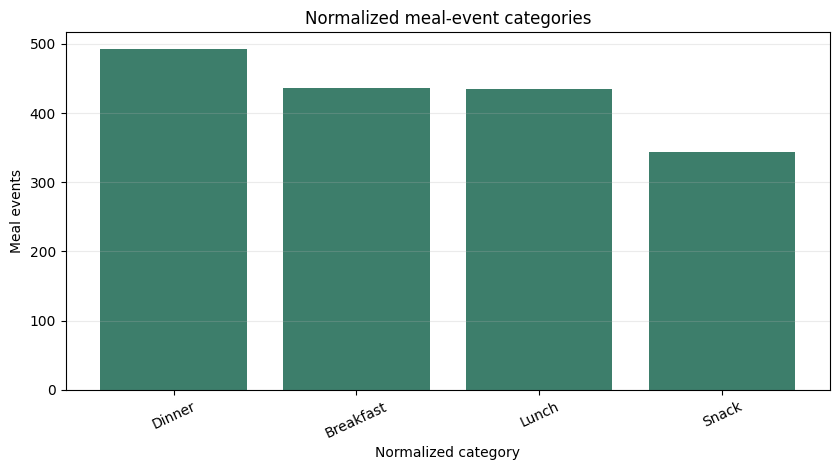

In [22]:
# Plot normalized meal-event categories.
meal_type_plot_data = meal_events["meal_type_normalized"].fillna("Not recorded").value_counts()
figure, axis = plt.subplots(figsize=(8.5, 4.8))
axis.bar(meal_type_plot_data.index.astype(str), meal_type_plot_data.values, color="#3D7E6B")
axis.set_title("Normalized meal-event categories")
axis.set_xlabel("Normalized category")
axis.set_ylabel("Meal events")
axis.tick_params(axis="x", rotation=25)
axis.grid(axis="y", alpha=0.25)
figure.tight_layout()
plt.show()

In [23]:
# Persist the tables that are read downstream.
food_entries.to_parquet(ARTIFACT_DIR / "food_entries.parquet", index=False)
meal_events.to_parquet(ARTIFACT_DIR / "meal_events.parquet", index=False)

display(food_entry_audit_summary)

,metric,value
0,food_entries,3259
1,meal_anchor_entries,1706
2,photo_only_entries,1553
3,image_references,3197
4,resolved_image_references,3194
5,broken_image_references,3
6,amount_consumed_above_declared_range,131
7,baseline_meal_events,1706


### Meal event rules

**Meal event construction rules**

| Topic | Rule |
| --- | --- |
| food entry definition | A published source row is a food entry when Meal Type, any of five core nutrition fields, Amount Consumed, or Image Path is present. |
| meal type normalization | Dictionary categories are matched case-insensitively; generic snack, snacks, and snack-number variants map to Snack; unknown labels remain explicit. |
| baseline meal event | Each entry with a meal label, core nutrition value, or Amount Consumed value is retained as one baseline meal event, one row per event. |
| Amount Consumed | Retain raw values and dictionary-range flags; do not scale or otherwise adjust nutrients from Amount Consumed. |
| photo linkage | Each food-entry row records whether its own image reference resolves to a file on disk; photo content is not used as a predictive feature (see the availability registry).

## Activity and static data integration


This section integrates activity measurements and subject-level Bio, Gut, and Microbiome data. Activity remains on the one-minute alignment grid built earlier in this notebook, with source/grid and value-origin provenance; missing activity is never interpreted as rest or zero.

The dictionary-supported MET transformation preserves the stored x10 value and creates `activity_met` by division by 10. Undocumented Intensity and Steps fields retain their source values without inferred units. High-dimensional Microbiome features remain at subject level rather than being duplicated across minute rows.

In [24]:
# --- Validate dictionary support for activity transformations ---

required_activity_fields = {
    "HR": "heart_rate",
    "Calories (Activity)": "activity_calories",
    "Mets": "activity_mets",
}
dictionary_rows = dynamic_dictionary.set_index("Field")
if not set(required_activity_fields).issubset(dictionary_rows.index):
    raise ValueError("Required activity fields are absent from the released dynamic dictionary.")
if "multiplied by 10" not in str(dictionary_rows.loc["Mets", "Description"]).casefold():
    raise ValueError("The released dictionary does not support the MET x10 conversion rule.")

# --- Record transformations and evidence without inferring undocumented units for Intensity or Steps ---

activity_field_rules = pd.DataFrame([
    {
        "source_field": "HR",
        "upstream_field": "heart_rate",
        "canonical_field": "heart_rate_bpm",
        "transformation": "identity",
        "canonical_unit": "beats_per_minute",
        "dictionary_status": "documented",
        "evidence": str(dictionary_rows.loc["HR", "Description"]).strip(),
    },
    {
        "source_field": "Calories (Activity)",
        "upstream_field": "activity_calories",
        "canonical_field": "activity_calories_per_minute",
        "transformation": "identity",
        "canonical_unit": "estimated_calories_per_minute",
        "dictionary_status": "documented",
        "evidence": str(dictionary_rows.loc["Calories (Activity)", "Description"]).strip(),
    },
    {
        "source_field": "Mets",
        "upstream_field": "activity_mets",
        "canonical_field": "activity_mets_stored_x10",
        "transformation": "identity_preserve_stored_value",
        "canonical_unit": "stored_MET_times_10",
        "dictionary_status": "documented",
        "evidence": str(dictionary_rows.loc["Mets", "Description"]).strip(),
    },
    {
        "source_field": "Mets",
        "upstream_field": "activity_mets",
        "canonical_field": "activity_met",
        "transformation": "divide_nonmissing_stored_value_by_10",
        "canonical_unit": "MET",
        "dictionary_status": "documented",
        "evidence": str(dictionary_rows.loc["Mets", "Description"]).strip(),
    },
    {
        "source_field": "Intensity",
        "upstream_field": "activity_intensity",
        "canonical_field": "activity_intensity_raw",
        "transformation": "identity_no_unit_in_released_dictionary",
        "canonical_unit": pd.NA,
        "dictionary_status": "not_listed_in_released_dynamic_dictionary",
        "evidence": pd.NA,
    },
    {
        "source_field": "Steps",
        "upstream_field": "steps",
        "canonical_field": "steps_raw",
        "transformation": "identity_no_unit_in_released_dictionary",
        "canonical_unit": pd.NA,
        "dictionary_status": "not_listed_in_released_dynamic_dictionary",
        "evidence": pd.NA,
    },
])

display(activity_field_rules[["source_field", "canonical_field", "transformation", "dictionary_status"]])

,source_field,canonical_field,transformation,dictionary_status
0,HR,heart_rate_bpm,identity,documented
1,Calories (Activity),activity_calories_per_minute,identity,documented
2,Mets,activity_mets_stored_x10,identity_preserve_stored_value,documented
3,Mets,activity_met,divide_nonmissing_stored_value_by_10,documented
4,Intensity,activity_intensity_raw,identity_no_unit_in_released_dictionary,not_listed_in_released_dynamic_dictionary
5,Steps,steps_raw,identity_no_unit_in_released_dictionary,not_listed_in_released_dynamic_dictionary


In [25]:
# Build a minute-level activity table while preserving source/grid provenance and missingness.
activity_key_columns = [
    "subject",
    "timestamp",
    "source_file",
    "source_row_index",
    "is_published_source_row",
    "is_inserted_grid_row",
    "row_provenance",
    "source_segment_id",
    "gap_id",
]
activity_canonical = dynamic_aligned_1min[activity_key_columns].copy()
activity_canonical["heart_rate_bpm"] = dynamic_aligned_1min["heart_rate"]
activity_canonical["activity_calories_per_minute"] = dynamic_aligned_1min["activity_calories"]
activity_canonical["activity_mets_stored_x10"] = dynamic_aligned_1min["activity_mets"]
activity_canonical["activity_met"] = dynamic_aligned_1min["activity_mets"].div(10)
activity_canonical["activity_intensity_raw"] = dynamic_aligned_1min["activity_intensity"]
activity_canonical["steps_raw"] = dynamic_aligned_1min["steps"]

# Carry each published-versus-grid value origin into the canonical activity schema.
activity_canonical["heart_rate_value_origin"] = dynamic_aligned_1min["heart_rate_value_origin"]
activity_canonical["activity_calories_value_origin"] = dynamic_aligned_1min["activity_calories_value_origin"]
activity_canonical["activity_mets_value_origin"] = dynamic_aligned_1min["activity_mets_value_origin"]
activity_canonical["activity_intensity_value_origin"] = dynamic_aligned_1min["activity_intensity_value_origin"]
activity_canonical["steps_value_origin"] = dynamic_aligned_1min["steps_value_origin"]
activity_canonical["met_conversion_applied"] = activity_canonical["activity_mets_stored_x10"].notna()
activity_canonical["met_conversion_rule"] = np.where(
    activity_canonical["met_conversion_applied"],
    "stored_value_divided_by_10",
    "not_applied_missing_value",
)
activity_canonical["has_project_interpolated_activity"] = False

canonical_activity_fields = [
    "heart_rate_bpm",
    "activity_calories_per_minute",
    "activity_mets_stored_x10",
    "activity_intensity_raw",
    "steps_raw",
]
for field in canonical_activity_fields:
    activity_canonical[f"{field}_missing"] = activity_canonical[field].isna()

activity_canonical["has_published_activity_value"] = (
    activity_canonical["is_published_source_row"]
    & activity_canonical[canonical_activity_fields].notna().any(axis=1)
)
activity_canonical["activity_row_status"] = np.select(
    [
        activity_canonical["is_inserted_grid_row"],
        activity_canonical["has_published_activity_value"],
    ],
    ["inserted_grid_row_no_activity_value", "published_source_row_with_activity_value"],
    default="published_source_row_without_activity_value",
)

In [26]:
# Derive source-schema variants from participant-level column availability.
source_presence_columns = {
    "heart_rate": "heart_rate_source_column_present",
    "activity_calories": "activity_calories_source_column_present",
    "activity_mets": "activity_mets_source_column_present",
    "activity_intensity": "activity_intensity_source_column_present",
    "steps": "steps_source_column_present",
}

activity_schema_by_subject = participant_missingness[["subject", *source_presence_columns.values()]].copy()
for column in source_presence_columns.values():
    activity_schema_by_subject[column] = activity_schema_by_subject[column].astype("boolean")
activity_schema_by_subject["met_intensity_schema"] = np.select(
    [
        activity_schema_by_subject["activity_mets_source_column_present"].fillna(False)
        & activity_schema_by_subject["activity_intensity_source_column_present"].fillna(False),
        activity_schema_by_subject["activity_mets_source_column_present"].fillna(False),
        activity_schema_by_subject["activity_intensity_source_column_present"].fillna(False),
    ],
    ["both_columns_present", "mets_only", "intensity_only"],
    default="neither_column_present",
)

published_activity = activity_canonical.loc[activity_canonical["is_published_source_row"]]
observed_counts = published_activity.groupby("subject", sort=True)[canonical_activity_fields].count()
observed_counts.columns = [f"{column}_published_nonmissing_count" for column in observed_counts.columns]
activity_schema_by_subject = activity_schema_by_subject.merge(
    observed_counts.reset_index(), on="subject", how="left", validate="one_to_one"
)

activity_field_coverage_records = []
for canonical_field, source_presence_field in [
    ("heart_rate_bpm", "heart_rate_source_column_present"),
    ("activity_calories_per_minute", "activity_calories_source_column_present"),
    ("activity_mets_stored_x10", "activity_mets_source_column_present"),
    ("activity_intensity_raw", "activity_intensity_source_column_present"),
    ("steps_raw", "steps_source_column_present"),
]:
    published_nonmissing = int(published_activity[canonical_field].notna().sum())
    activity_field_coverage_records.append({
        "canonical_field": canonical_field,
        "subjects_with_source_column": int(activity_schema_by_subject[source_presence_field].fillna(False).sum()),
        "published_nonmissing_values": published_nonmissing,
        "published_rows": len(published_activity),
        "published_nonmissing_fraction": published_nonmissing / len(published_activity),
        "inserted_grid_nonmissing_values": int(
            activity_canonical.loc[activity_canonical["is_inserted_grid_row"], canonical_field].notna().sum()
        ),
    })
activity_field_coverage = pd.DataFrame(activity_field_coverage_records)

display(activity_field_coverage)
display(activity_schema_by_subject["met_intensity_schema"].value_counts().rename_axis("schema").reset_index(name="subjects"))
print(
    f"Constructed activity_canonical with {len(activity_canonical):,} rows and "
    f"{activity_canonical['subject'].nunique()} subjects; "
    f"{int(activity_canonical['is_inserted_grid_row'].sum()):,} inserted grid rows retain missing activity values."
)

,canonical_field,subjects_with_source_column,published_nonmissing_values,published_rows,published_nonmissing_fraction,inserted_grid_nonmissing_values
0,heart_rate_bpm,45,610256,687580,0.887542,0
1,activity_calories_per_minute,44,652134,687580,0.948448,0
2,activity_mets_stored_x10,34,501078,687580,0.728756,0
3,activity_intensity_raw,11,156710,687580,0.227915,0
4,steps_raw,1,5655,687580,0.008224,0


,schema,subjects
0,mets_only,34
1,intensity_only,11


Constructed activity_canonical with 706,312 rows and 45 subjects; 18,732 inserted grid rows retain missing activity values.


In [27]:
# Canonicalize each static table from the upstream mapping while retaining source-name traceability.
def canonicalize_static_table(raw_frame, table_name, source_relative_path):
    mapping = column_mapping.loc[column_mapping["table"].eq(table_name)].copy()
    normalized_actual = {str(column).strip(): column for column in raw_frame.columns}
    if len(normalized_actual) != len(raw_frame.columns):
        raise ValueError(f"Whitespace-normalized source columns collide in {table_name}.")

    required_raw = mapping["raw_column_name"].astype(str).str.strip().tolist()
    missing_from_source = sorted(set(required_raw).difference(normalized_actual))
    unexpected_source = sorted(set(normalized_actual).difference(required_raw))
    if missing_from_source or unexpected_source:
        raise ValueError(
            f"Static mapping mismatch for {table_name}: missing={missing_from_source}, unexpected={unexpected_source}"
        )

    rename_map = {
        normalized_actual[str(row.raw_column_name).strip()]: str(row.canonical_column_name).strip()
        for row in mapping.itertuples(index=False)
    }
    canonical = raw_frame.rename(columns=rename_map).copy()
    canonical["subject"] = pd.to_numeric(canonical["subject"], errors="raise").astype(int)
    if canonical["subject"].duplicated().any():
        raise ValueError(f"Duplicate subject keys found in {table_name}.")

    value_fields = [column for column in canonical.columns if column != "subject"]
    canonical["static_source_table"] = table_name
    canonical["static_source_relative_path"] = source_relative_path
    canonical["in_dynamic_cohort"] = canonical["subject"].isin(dynamic_subjects)
    canonical["static_record_present"] = True
    canonical["nonmissing_value_count"] = canonical[value_fields].notna().sum(axis=1)
    canonical["all_value_fields_missing"] = canonical[value_fields].isna().all(axis=1)
    canonical["static_availability_status"] = np.select(
        [
            ~canonical["in_dynamic_cohort"],
            canonical["all_value_fields_missing"],
        ],
        ["outside_dynamic_cohort", "record_present_all_values_missing"],
        default="record_present_with_values",
    )

    traceability = mapping[[
        "table", "raw_column_name", "canonical_column_name", "mapping_action", "notes"
    ]].copy()
    traceability["source_relative_path"] = source_relative_path
    traceability["actual_source_column_name"] = traceability["raw_column_name"].map(
        lambda name: normalized_actual[str(name).strip()]
    )
    return canonical, traceability, value_fields


dynamic_subjects = pd.Index(sorted(dynamic_aligned_1min["subject"].unique()), name="subject")
bio_canonical, bio_trace, bio_value_fields = canonicalize_static_table(
    bio_raw, "bio", "CGMacros/bio.csv"
)
gut_health_canonical, gut_trace, gut_value_fields = canonicalize_static_table(
    gut_health_raw, "gut_health", "CGMacros/gut_health_test.csv"
)
microbiome_canonical, microbiome_trace, microbiome_value_fields = canonicalize_static_table(
    microbiome_raw, "microbiome", "CGMacros/microbes.csv"
)
static_column_traceability = pd.concat(
    [bio_trace, gut_trace, microbiome_trace], ignore_index=True
)

In [28]:
# Preserve dictionary-confirmed Bio error flags without altering source values.
confirmed_bio_errors = outlier_candidates.loc[
    outlier_candidates["data_source"].eq("bio")
    & outlier_candidates["evidence_class"].astype(str).str.startswith("confirmed_")
].groupby("subject").size().rename("confirmed_dictionary_error_field_count")
bio_canonical = bio_canonical.merge(
    confirmed_bio_errors.reset_index(), on="subject", how="left", validate="one_to_one"
)
bio_canonical["confirmed_dictionary_error_field_count"] = (
    bio_canonical["confirmed_dictionary_error_field_count"].fillna(0).astype(int)
)

# Validate dictionary encoding domains; missing values remain missing and are never converted to zero.
gut_allowed_values = {
    int(value)
    for text in gut_dictionary["Value"].dropna().astype(str)
    for value in re.findall(r"(\d+)\s*=", text)
}
microbiome_allowed_values = {
    int(value)
    for text in microbiome_dictionary["Range"].dropna().astype(str)
    for value in re.findall(r"(\d+)\s*=", text)
}
gut_observed_values = set(pd.unique(gut_health_canonical[gut_value_fields].stack().dropna()))
microbiome_observed_values = set(pd.unique(microbiome_canonical[microbiome_value_fields].stack().dropna()))
if not gut_observed_values.issubset(gut_allowed_values):
    raise ValueError(f"Gut values outside dictionary encoding: {sorted(gut_observed_values - gut_allowed_values)}")
if not microbiome_observed_values.issubset(microbiome_allowed_values):
    raise ValueError(
        f"Microbiome values outside dictionary encoding: {sorted(microbiome_observed_values - microbiome_allowed_values)}"
    )

In [29]:
# Build one subject-level table for the dynamic cohort; high-dimensional values are not copied to minute rows.
static_canonical = dynamic_subjects.to_frame(index=False)
static_availability = dynamic_subjects.to_frame(index=False)
static_canonical_tables = {
    "bio": (bio_canonical, bio_value_fields),
    "gut": (gut_health_canonical, gut_value_fields),
    "microbiome": (microbiome_canonical, microbiome_value_fields),
}
static_coverage_records = []
excluded_records = []

def integrate_static_source(short_name, table, value_fields, static_canonical, static_availability):
    """Add one static source without expanding its values to minute-level rows."""
    cohort_table = table.loc[table["in_dynamic_cohort"]].copy()
    value_subset = cohort_table[["subject", *value_fields]].rename(
        columns={field: f"{short_name}__{field}" for field in value_fields}
    )
    static_canonical = static_canonical.merge(
        value_subset, on="subject", how="left", validate="one_to_one"
    )

    availability_subset = cohort_table[[
        "subject", "static_record_present", "all_value_fields_missing", "nonmissing_value_count"
    ]].rename(columns={
        "static_record_present": f"{short_name}_record_present",
        "all_value_fields_missing": f"{short_name}_all_value_fields_missing",
        "nonmissing_value_count": f"{short_name}_nonmissing_value_count",
    })
    static_availability = static_availability.merge(
        availability_subset, on="subject", how="left", validate="one_to_one"
    )
    static_availability[f"{short_name}_record_present"] = (
        static_availability[f"{short_name}_record_present"].fillna(False).astype(bool)
    )
    static_availability[f"{short_name}_all_value_fields_missing"] = (
        static_availability[f"{short_name}_all_value_fields_missing"].fillna(False).astype(bool)
    )
    static_availability[f"{short_name}_values_available"] = (
        static_availability[f"{short_name}_record_present"]
        & ~static_availability[f"{short_name}_all_value_fields_missing"]
    )

    outside = table.loc[~table["in_dynamic_cohort"], [
        "subject", "static_source_table", "static_source_relative_path",
        "nonmissing_value_count", "all_value_fields_missing", "static_availability_status"
    ]]
    coverage_record = {
        "static_table": short_name,
        "source_rows": len(table),
        "unique_subjects": table["subject"].nunique(),
        "dynamic_cohort_subjects": len(dynamic_subjects),
        "cohort_records_present": int(cohort_table["static_record_present"].sum()),
        "cohort_records_with_values": int((~cohort_table["all_value_fields_missing"]).sum()),
        "cohort_all_value_fields_missing": int(cohort_table["all_value_fields_missing"].sum()),
        "outside_dynamic_cohort_rows": int((~table["in_dynamic_cohort"]).sum()),
        "value_field_count": len(value_fields),
        "cohort_missing_value_cells": int(cohort_table[value_fields].isna().sum().sum()),
    }
    return static_canonical, static_availability, outside, coverage_record


for short_name, (table, value_fields) in static_canonical_tables.items():
    static_canonical, static_availability, outside, coverage_record = integrate_static_source(
        short_name, table, value_fields, static_canonical, static_availability
    )
    excluded_records.append(outside)
    static_coverage_records.append(coverage_record)

static_excluded_rows = pd.concat(excluded_records, ignore_index=True)
static_coverage = pd.DataFrame(static_coverage_records)
static_canonical = static_canonical.merge(
    static_availability, on="subject", how="left", validate="one_to_one"
)

# Confirm that no absent or fully missing microbiome value has been encoded as absence.
microbiome_missing_before = int(microbiome_raw.drop(columns=[microbiome_raw.columns[0]]).isna().sum().sum())
microbiome_missing_after = int(microbiome_canonical[microbiome_value_fields].isna().sum().sum())
assert microbiome_missing_before == microbiome_missing_after

display(static_coverage)
if not static_excluded_rows.empty:
    display(static_excluded_rows)
print(
    f"Created one-row-per-subject canonical tables for {len(bio_canonical)} Bio, "
    f"{len(gut_health_canonical)} Gut, and {len(microbiome_canonical)} Microbiome source records. "
    f"The integrated static_canonical contains {len(static_canonical)} dynamic-cohort subjects; "
    f"{len(static_excluded_rows)} out-of-cohort static rows were retained only in the exclusion audit."
)

,static_table,source_rows,unique_subjects,dynamic_cohort_subjects,cohort_records_present,cohort_records_with_values,cohort_all_value_fields_missing,outside_dynamic_cohort_rows,value_field_count,cohort_missing_value_cells
0,bio,45,45,45,45,45,0,0,23,0
1,gut,47,47,45,45,42,3,2,22,66
2,microbiome,45,45,45,45,44,1,0,1979,1979


,subject,static_source_table,static_source_relative_path,nonmissing_value_count,all_value_fields_missing,static_availability_status
0,24,gut_health,CGMacros/gut_health_test.csv,0,True,outside_dynamic_cohort
1,25,gut_health,CGMacros/gut_health_test.csv,0,True,outside_dynamic_cohort


Created one-row-per-subject canonical tables for 45 Bio, 47 Gut, and 45 Microbiome source records. The integrated static_canonical contains 45 dynamic-cohort subjects; 2 out-of-cohort static rows were retained only in the exclusion audit.


In [30]:
# Create subject-level merge coverage.
dynamic_counts = activity_canonical.groupby("subject", sort=True).agg(
    aligned_minute_rows=("timestamp", "size"),
    published_source_rows=("is_published_source_row", "sum"),
    inserted_grid_rows=("is_inserted_grid_row", "sum"),
    published_rows_with_any_activity=("has_published_activity_value", "sum"),
).reset_index()

merge_coverage = dynamic_counts.merge(
    activity_schema_by_subject, on="subject", how="left", validate="one_to_one"
).merge(
    static_availability, on="subject", how="left", validate="one_to_one"
)

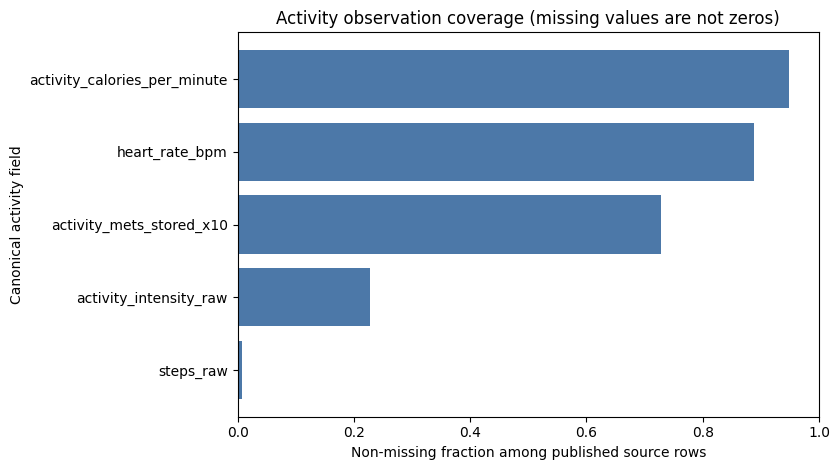

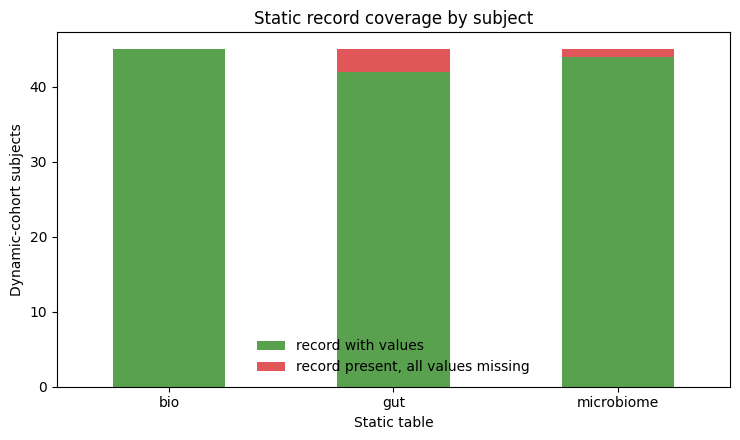

In [31]:
# Plot compact coverage summaries without treating missing activity as zero-valued activity.
plt.figure(figsize=(8.5, 4.8))
plot_activity = activity_field_coverage.sort_values("published_nonmissing_fraction", ascending=True)
plt.barh(plot_activity["canonical_field"], plot_activity["published_nonmissing_fraction"], color="#4C78A8")
plt.xlabel("Non-missing fraction among published source rows")
plt.ylabel("Canonical activity field")
plt.title("Activity observation coverage (missing values are not zeros)")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7.5, 4.5))
static_plot = static_coverage.set_index("static_table")[[
    "cohort_records_with_values", "cohort_all_value_fields_missing"
]]
static_plot.plot(kind="bar", stacked=True, color=["#59A14F", "#E15759"], ax=plt.gca())
plt.ylabel("Dynamic-cohort subjects")
plt.xlabel("Static table")
plt.title("Static record coverage by subject")
plt.xticks(rotation=0)
plt.legend(["record with values", "record present, all values missing"], frameon=False)
plt.tight_layout()
plt.show()


In [32]:
# --- Persist activity and static integration outputs ---

output_objects = {
    "activity_canonical.parquet": activity_canonical,
    "static_column_traceability.csv": static_column_traceability,
    "bio_canonical.parquet": bio_canonical,
    "gut_health_canonical.parquet": gut_health_canonical,
    "microbiome_canonical.parquet": microbiome_canonical,
    "static_canonical.parquet": static_canonical,
    "static_coverage.csv": static_coverage,
    "merge_coverage.csv": merge_coverage,
}
for file_name, frame in output_objects.items():
    output_path = ARTIFACT_DIR / file_name
    if output_path.suffix == ".parquet":
        frame.to_parquet(output_path, index=False)
    else:
        frame.to_csv(output_path, index=False)

# --- Display static-source availability counts ---

display(static_availability[[
    "bio_values_available", "gut_values_available", "microbiome_values_available"
]].sum().rename("subjects_with_values").rename_axis("static_source").reset_index())


,static_source,subjects_with_values
0,bio_values_available,45
1,gut_values_available,42
2,microbiome_values_available,44


## Feature availability and leakage boundaries


This section creates a field-level `availability_registry` that separates event time from availability time. A value's presence in the released dataset does not establish that it was available to a prediction system at time \(t\). The registry defines causal-use boundaries only.

**Policy terms used in the registry**

| Term | Definition |
| --- | --- |
| `event_time` | When the underlying physiological, behavioral, meal, or collection event occurred in the released timeline. |
| `availability_time` | The earliest time the value could actually be supplied to the prediction system; this may be later than event time. |
| `offline_event_time_use` | Whether a retrospective experiment may use the value after enforcing a causal event-time cutoff. |
| `real_time_availability_status` | Whether released sources establish operational arrival timing for deployment; event timestamps alone do not establish this. |
| `offline_analysis_only` | True when the current evidence supports retrospective analysis but not real-time availability at prediction time. |


In [33]:
# --- Locate the released dictionary PDF ---

dictionary_pdf_path = DATA_ROOT / "DataDictionary.pdf"
if not dictionary_pdf_path.is_file():
    raise FileNotFoundError("The released DataDictionary.pdf is required as a formal source.")

# --- Confirm timestamp documentation and derive the dynamic field catalog ---

timestamp_rows = dynamic_dictionary.loc[dynamic_dictionary["Field"].astype(str).str.strip().eq("Timestamp")]
if len(timestamp_rows) != 1:
    raise ValueError("The dynamic dictionary must contain exactly one Timestamp definition.")
timestamp_description = str(timestamp_rows.iloc[0]["Description"]).strip()
if "randomly shifted" not in timestamp_description.casefold():
    raise ValueError("The released dictionary does not confirm randomly shifted timestamps.")

dynamic_catalog = (
    column_mapping.loc[column_mapping["table"].eq("dynamic"), [
        "raw_column_name", "canonical_column_name", "analytic_role"
    ]]
    .assign(
        raw_column_name=lambda frame: frame["raw_column_name"].astype(str).str.strip(),
        canonical_column_name=lambda frame: frame["canonical_column_name"].astype(str).str.strip(),
    )
    .drop_duplicates("canonical_column_name")
    .reset_index(drop=True)
)

# --- Derive the static field catalog ---

static_catalog = static_column_traceability[[
    "table", "raw_column_name", "canonical_column_name", "source_relative_path"
]].copy()
static_catalog = static_catalog.rename(columns={"canonical_column_name": "canonical_field"})
static_catalog["raw_column_name"] = static_catalog["raw_column_name"].astype(str).str.strip()
static_catalog["canonical_field"] = static_catalog["canonical_field"].astype(str).str.strip()
static_catalog = static_catalog.loc[~static_catalog["canonical_field"].eq("subject")].reset_index(drop=True)

In [34]:
# Build a field-level registry that separates event-time eligibility from verified real-time availability.
registry_records = []


def add_registry_record(
    feature_group,
    candidate_feature,
    source_object,
    source_field,
    observation_level,
    event_time_definition,
    availability_time_definition,
    availability_evidence_status,
    offline_event_time_use,
    safe_for_prediction_at_t,
    real_time_availability_status,
    model_input_scope,
    offline_analysis_only,
    unresolved_timing_assumption,
    leakage_boundary,
    evidence_source,
    dictionary_documented,
    notes="",
):
    registry_records.append({
        "feature_group": feature_group,
        "candidate_feature": candidate_feature,
        "source_object": source_object,
        "source_field": source_field,
        "observation_level": observation_level,
        "event_time_definition": event_time_definition,
        "availability_time_definition": availability_time_definition,
        "availability_evidence_status": availability_evidence_status,
        "offline_event_time_use": offline_event_time_use,
        "safe_for_prediction_at_t": safe_for_prediction_at_t,
        "real_time_availability_status": real_time_availability_status,
        "model_input_scope": model_input_scope,
        "offline_analysis_only": bool(offline_analysis_only),
        "unresolved_timing_assumption": unresolved_timing_assumption,
        "leakage_boundary": leakage_boundary,
        "evidence_source": evidence_source,
        "dictionary_documented": bool(dictionary_documented),
        "notes": notes,
    })


dynamic_dictionary_fields = set(dynamic_dictionary["Field"].astype(str).str.strip().str.casefold())

def dynamic_is_documented(raw_name):
    return str(raw_name).strip().casefold() in dynamic_dictionary_fields

In [35]:
# Glucose values may be used retrospectively only when their event time is at or before the prediction cutoff.
for field in ["libre_gl", "dexcom_gl"]:
    source_row = dynamic_catalog.loc[dynamic_catalog["canonical_column_name"].eq(field)].iloc[0]
    add_registry_record(
        "glucose_history",
        field,
        "dynamic_aligned_1min",
        field,
        "subject_minute",
        "Released shifted CGM timestamp attached to the glucose value.",
        "No ingestion or device-to-model arrival timestamp is provided.",
        "event_time_documented_arrival_time_unreported",
        "allowed_only_when_event_time_is_at_or_before_t",
        "conditional_strictly_historical",
        "not_established_from_released_sources",
        "candidate_with_causal_cutoff",
        True,
        "Real-time sensor latency and whether any publisher-side interpolation or filtering used future anchors are not documented.",
        "Exclude values after t and all target-horizon glucose; resampling alone does not establish causality.",
        "DataDictionary_CGMacros-00X.csv; dynamic_aligned_1min",
        dynamic_is_documented(source_row["raw_column_name"]),
    )

# Minute activity values remain separate and inherit the released timestamp; device/export latency is unresolved.
for row in activity_field_rules.itertuples(index=False):
    add_registry_record(
        "activity_minute",
        str(row.canonical_field),
        "activity_canonical",
        str(row.canonical_field),
        "subject_minute",
        "Released shifted minute timestamp attached to the activity value.",
        "No device-to-export, upload, or model-arrival timestamp is provided.",
        "event_time_or_past_minute_semantics_arrival_time_unreported",
        "allowed_only_when_event_time_is_at_or_before_t",
        "conditional_strictly_historical",
        "not_established_from_released_sources",
        "candidate_with_causal_cutoff",
        True,
        "Upstream aggregation/filter direction and delivery latency are not fully documented; Intensity and Steps also lack released dictionary definitions.",
        "Do not use future minutes, centered filters, completed-day totals, or missing-as-zero substitutions.",
        "activity_field_rules.csv; DataDictionary_CGMacros-00X.csv",
        str(row.dictionary_status) == "documented",
        "MET stored-x10 and converted MET are alternative representations of the same source signal.",
    )

In [36]:
# Meal-log fields use the recorded row time only as an event-time proxy; creation/upload timing is not provided.
meal_log_fields = ["meal_type", "meal_calories", "carbs", "protein", "fat", "fiber", "sugar"]
for field in meal_log_fields:
    source_row = dynamic_catalog.loc[dynamic_catalog["canonical_column_name"].eq(field)].iloc[0]
    add_registry_record(
        "meal_log",
        field,
        "food_entries",
        field,
        "meal_event",
        "Released shifted timestamp on the food-entry row.",
        "Record creation and upload time are not present in the released tables.",
        "event_time_proxy_only_upload_time_unreported",
        "allowed_only_after_the_record_is_known_and_event_time_is_at_or_before_t",
        "conditional_after_record_creation",
        "not_established_from_released_sources",
        "candidate_only_with_explicit_availability_assumption",
        True,
        "The released row timestamp is not proof that the final logged content was available to a model at that instant.",
        "Do not backfill a completed meal log into predictions made before the record existed.",
        "DataDictionary_CGMacros-00X.csv; food_entries",
        dynamic_is_documented(source_row["raw_column_name"]),
    )

# Final consumption and photos require stricter boundaries because completion/start-end timing is unresolved.
amount_source = dynamic_catalog.loc[
    dynamic_catalog["canonical_column_name"].eq("amount_consumed")
].iloc[0]
add_registry_record(
    "meal_completion",
    "amount_consumed",
    "food_entries",
    "amount_consumed",
    "meal_event",
    "Meal-row timestamp; the field semantically estimates the final proportion consumed.",
    "Not earlier than meal completion, but completion and upload timestamps are absent.",
    "completion_required_exact_availability_unreported",
    "not_allowed_before_verified_meal_completion",
    "no_before_meal_completion",
    "not_established_from_released_sources",
    "candidate_only_with_verified_completion_time",
    True,
    "The dataset does not establish when the final percentage became known.",
    "Never use final Amount Consumed for a prediction made before meal completion; do not use it to retroactively scale nutrients.",
    "DataDictionary_CGMacros-00X.csv; food_entries",
    dynamic_is_documented(amount_source["raw_column_name"]),
)

image_source = dynamic_catalog.loc[dynamic_catalog["canonical_column_name"].eq("image_path")].iloc[0]
add_registry_record(
    "meal_photo",
    "meal_image_content",
    "food_entries",
    "image_path",
    "meal_or_photo_event",
    "Released row timestamp; the dictionary allows a photo associated with meal start or end.",
    "Capture, upload, and feature-extraction completion times are absent; start versus end is not identified per image.",
    "start_or_end_semantics_exact_availability_unreported",
    "not_allowed_without_verified_capture_role_and_availability",
    "no_without_verified_photo_timing",
    "not_established_from_released_sources",
    "offline_only_until_photo_timing_is_verified",
    True,
    "A meal-end photo is future information for a prediction at meal start, and file existence does not establish feature availability.",
    "Image paths and participant folder structure must not be used as predictive strings; content features need a causal extraction timestamp.",
    "DataDictionary_CGMacros-00X.csv; food_entries",
    dynamic_is_documented(image_source["raw_column_name"]),
)

In [37]:
# Register temporal candidates separately so shifted calendar values cannot acquire real-world meaning.
add_registry_record(
    "temporal_context",
    "relative_elapsed_time_within_subject",
    "dynamic_aligned_1min",
    "timestamp",
    "subject_minute",
    "Difference between released shifted timestamps within a participant.",
    "Available with the current or earlier timestamp in the released sequence.",
    "relative_order_supported_by_released_timestamp",
    "allowed_when_computed_using_timestamps_at_or_before_t",
    "conditional_causal_relative_time",
    "not_established_from_released_sources",
    "candidate_with_causal_cutoff",
    True,
    "The release documents random shifting but not a real-time clock feed.",
    "Use relative order or elapsed duration only; do not reinterpret the shifted date as the true calendar.",
    "DataDictionary_CGMacros-00X.csv; DataDictionary.pdf",
    True,
)
add_registry_record(
    "temporal_context",
    "shifted_clock_time_feature",
    "dynamic_aligned_1min",
    "timestamp",
    "subject_minute",
    "Clock component of the released shifted timestamp.",
    "Present in the released table, but preservation of true local clock time is not explicitly established.",
    "shift_effect_on_clock_time_unresolved",
    "allowed_only_as_a_shifted_sequence_feature_with_explicit_assumption",
    "conditional_shifted_clock_only",
    "not_established_from_released_sources",
    "candidate_only_with_documented_assumption",
    True,
    "Whether the random shift preserves real local clock time is not confirmed by the released dictionary.",
    "Do not label this feature as true circadian or local clock time without supporting evidence.",
    "DataDictionary_CGMacros-00X.csv; DataDictionary.pdf",
    True,
)
add_registry_record(
    "temporal_context",
    "calendar_season_holiday_or_real_date",
    "dynamic_aligned_1min",
    "timestamp",
    "subject_minute",
    "Calendar components of a randomly shifted released timestamp.",
    "The released calendar date is available but is not the true study date.",
    "known_shifted_calendar_not_real_calendar",
    "not_allowed_as_real_calendar_context",
    "no_real_calendar_interpretation",
    "not_applicable",
    "excluded_from_model_features",
    False,
    "No mapping back to true calendar dates is provided.",
    "Do not derive real season, weekday-specific holiday, holiday, or real-date context from shifted dates.",
    "DataDictionary_CGMacros-00X.csv; DataDictionary.pdf",
    True,
)


In [38]:
# Classify each subject-level static field; precise collection/result availability is absent from the row schema.
baseline_bio_fields = {
    "age", "gender", "bmi", "body_weight_lb", "height_in", "self_identified_race_ethnicity"
}

microbiome_registered = False
n_microbiome_fields = int(static_catalog["table"].eq("microbiome").sum())
for row in static_catalog.itertuples(index=False):
    table_name = str(row.table)
    field = str(row.canonical_field)
    if table_name == "microbiome":
        if microbiome_registered:
            continue
        microbiome_registered = True
        field = "microbiome_indicators"
    if table_name == "bio" and field in baseline_bio_fields:
        group = "bio_baseline"
        event_time = "Study-start baseline according to the Bio dictionary; no field-level date is stored."
        availability_time = "Assumed available after enrollment measurement; exact timestamp is absent."
        evidence_status = "baseline_semantics_exact_timestamp_absent"
        offline_use = "allowed_only_for_predictions_after_confirmed_baseline_availability"
        safe_status = "conditional_after_baseline_availability"
        scope = "candidate_with_baseline_cutoff"
        offline_only = False
        unresolved = "The exact enrollment measurement time relative to dynamic monitoring is not encoded."
        boundary = "Do not backfill into predictions before the participant-level measurement was available."
    elif table_name == "bio":
        group = "bio_lab_or_fingerstick"
        event_time = "Laboratory/fingerstick collection context; static rows lack a complete dated event timestamp."
        availability_time = "Result-return time is not included; collection time-of-day is not an availability timestamp."
        evidence_status = "collection_context_partial_result_time_unreported"
        offline_use = "allowed_only_under_a_documented_pre_prediction_result_availability_assumption"
        safe_status = "conditional_after_verified_result_availability"
        scope = "offline_baseline_candidate_until_timing_verified"
        offline_only = True
        unresolved = "The released sources do not identify when each result was returned relative to CGM prediction times."
        boundary = "Do not use a laboratory or fingerstick result before its verified result-availability time."
    elif table_name == "gut_health":
        group = "gut_health_static"
        event_time = "Subject-level Gut report value; no sample/assay date is stored in the table."
        availability_time = "Sample collection, assay completion, and report-return times are absent."
        evidence_status = "sample_and_report_timing_unreported"
        offline_use = "offline_only_until_pre_prediction_availability_is_established"
        safe_status = "no_unless_available_before_prediction_period"
        scope = "offline_subject_level_candidate"
        offline_only = True
        unresolved = "Temporal ordering of Gut results versus dynamic monitoring is not established in the released table."
        boundary = "Do not backfill a later Gut report into earlier prediction times."
    elif table_name == "microbiome":
        group = "microbiome_static"
        event_time = "Subject-level assay result; no stool-sample or assay date is stored in the table."
        availability_time = "Stool collection, assay completion, and result-return times are absent."
        evidence_status = "sample_and_assay_timing_unreported"
        offline_use = "offline_only_until_pre_prediction_availability_is_established"
        safe_status = "no_unless_available_before_prediction_period"
        scope = "offline_high_dimensional_subject_level_candidate"
        offline_only = True
        unresolved = "Temporal ordering of the microbiome assay versus dynamic monitoring is not established."
        boundary = "Do not backfill assay results; keep missing values distinct from binary absence and fit any reduction on training subjects only."
    else:
        raise ValueError(f"Unexpected static table: {table_name}")

    add_registry_record(
        group,
        field if table_name == "microbiome" else f"{table_name}__{field}",
        "static_canonical",
        field,
        "subject_static",
        event_time,
        availability_time,
        evidence_status,
        offline_use,
        safe_status,
        "not_established_from_released_sources",
        scope,
        offline_only,
        unresolved,
        boundary + " Static repetition across minutes does not create independent participants.",
        f"{row.source_relative_path}; released static dictionary; static_column_traceability.csv",
        True,
    )


In [39]:
# Identifiers and audit metadata remain available for joins/checks but are excluded from model inputs.
for field, source in [
    ("subject", "dynamic/static keys"),
    ("source_file", "dynamic_aligned_1min"),
    ("source_row_index", "dynamic_aligned_1min"),
    ("source_export_index", "dynamic_canonical"),
    ("source_record_index", "dynamic_canonical"),
]:
    add_registry_record(
        "identifier_or_source_metadata",
        field,
        source,
        field,
        "row_or_subject_key",
        "Not a biological event-time feature.",
        "Available in the released processing table.",
        "available_as_audit_metadata",
        "not_allowed_as_a_predictive_feature",
        "no_identifier_or_metadata",
        "not_applicable",
        "excluded_from_model_features",
        False,
        "None; exclusion is a design rule.",
        "Identifiers and paths can encode participant, source, or export identity and cause identity leakage.",
        "upstream canonical schemas",
        False,
    )

In [40]:
# Alignment metadata that depends on a future endpoint cannot be used at the start of a gap.
future_gap_fields = [
    "gap_id", "gap_interval_minutes", "gap_missing_grid_minutes",
    "gap_gt_15_minutes", "gap_gt_60_minutes", "gap_gt_1440_minutes",
]
for field in future_gap_fields:
    if field in dynamic_aligned_1min.columns:
        add_registry_record(
            "alignment_audit",
            field,
            "dynamic_aligned_1min",
            field,
            "subject_minute_or_gap",
            "Derived from a gap bounded by the previous and next published observations.",
            "Known only after the next observation closes the gap.",
            "future_endpoint_required",
            "not_allowed_before_gap_closure",
            "no_future_dependent_gap_metadata",
            "not_applicable",
            "excluded_from_model_features",
            False,
            "A causal alternative would need to use only time since the last observation.",
            "Using total gap length or threshold class during the gap reveals a future observation time.",
            "dynamic_aligned_1min construction provenance",
            False,
        )

audit_fields = [
    "is_inserted_grid_row", "row_provenance", "has_project_interpolated_values",
    *[field for field in dynamic_aligned_1min.columns if field.endswith("_value_origin")],
]
for field in dict.fromkeys(audit_fields):
    add_registry_record(
        "alignment_audit",
        field,
        "dynamic_aligned_1min",
        field,
        "subject_minute",
        "Processing provenance for the released/aligned row.",
        "Available during offline table construction; real-time generation is not defined.",
        "offline_processing_metadata",
        "audit_only_not_a_default_predictive_feature",
        "no_audit_metadata_by_default",
        "not_applicable",
        "excluded_from_model_features",
        False,
        "A downstream causal missingness feature must be defined separately using information available by t.",
        "Provenance can reveal post-processing state and must not be mistaken for a sensor measurement.",
        "dynamic_aligned_1min provenance columns",
        False,
    )

In [41]:
# Explicitly register common derived-feature boundaries without constructing those features here.
derived_policies = [
    (
        "trailing_history_summary", "allowed_if_all_source_times_are_at_or_before_t",
        "conditional_causal_trailing_only", "candidate_only_with_trailing_window",
        False, "Every source row in the aggregation must satisfy event_time <= t.",
        "Never center the window or include observations from the forecast horizon."
    ),
    (
        "whole_day_activity_summary", "not_allowed_before_end_of_the_day",
        "no_before_day_completion", "offline_or_next_day_only",
        True, "Day-completion time and intended prediction cutoff must be explicit.",
        "A completed-day total leaks later activity into an earlier prediction on the same day."
    ),
    (
        "centered_or_future_anchored_imputation", "not_allowed",
        "no_future_anchored_imputation", "excluded_from_causal_features",
        False, "Interpolation anchors and filter direction are not documented for the released pipeline.",
        "Fit or compute imputation causally within each split; a one-minute grid alone does not remove leakage."
    ),
    (
        "learned_preprocessing_parameters", "allowed_only_when_fit_on_the_corresponding_training_set",
        "conditional_train_fitted_only", "training_pipeline_control",
        False, "The relevant training set depends on the later evaluation design.",
        "Imputation, scaling, feature selection, and dimensionality reduction must not learn from validation/test subjects or future periods."
    ),
]
for field, offline_use, safe_status, scope, offline_only, unresolved, boundary in derived_policies:
    add_registry_record(
        "derived_feature_policy",
        field,
        "future_modeling_pipeline",
        field,
        "derived_feature_or_parameter",
        "Defined by the source rows used in the derivation.",
        "Available only after all source rows or training data used by the derivation are available.",
        "method_dependent",
        offline_use,
        safe_status,
        "method_dependent",
        scope,
        offline_only,
        unresolved,
        boundary,
        "causal modeling policy",
        False,
    )

availability_registry = pd.DataFrame(registry_records).drop(columns=["evidence_source", "notes"])
availability_registry["n_fields"] = 1
availability_registry.loc[availability_registry["feature_group"].eq("microbiome_static"), "n_fields"] = n_microbiome_fields
availability_registry.insert(
    0,
    "registry_id",
    [f"AV{number:04d}" for number in range(1, len(availability_registry) + 1)],
)

print(
    f"Constructed availability_registry with {len(availability_registry):,} field/policy rows across "
    f"{availability_registry['feature_group'].nunique()} feature groups."
)
display(
    availability_registry.groupby([
        "feature_group", "model_input_scope", "offline_analysis_only"
    ]).size().rename("registry_rows").reset_index()
)


Constructed availability_registry with 91 field/policy rows across 13 feature groups.


,feature_group,model_input_scope,offline_analysis_only,registry_rows
0,activity_minute,candidate_with_causal_cutoff,True,6
1,alignment_audit,excluded_from_model_features,False,16
2,bio_baseline,candidate_with_baseline_cutoff,False,6
3,bio_lab_or_fingerstick,offline_baseline_candidate_until_timing_verified,True,17
4,derived_feature_policy,candidate_only_with_trailing_window,False,1
5,derived_feature_policy,excluded_from_causal_features,False,1
6,derived_feature_policy,offline_or_next_day_only,True,1
7,derived_feature_policy,training_pipeline_control,False,1
8,glucose_history,candidate_with_causal_cutoff,True,2
9,gut_health_static,offline_subject_level_candidate,True,22


In [42]:
# Validate required leakage boundaries, summarize the registry, and save auditable outputs.
required_registry_columns = [
    "registry_id", "feature_group", "candidate_feature", "source_object", "source_field",
    "observation_level", "event_time_definition", "availability_time_definition",
    "availability_evidence_status", "offline_event_time_use", "safe_for_prediction_at_t",
    "real_time_availability_status", "model_input_scope", "offline_analysis_only",
    "unresolved_timing_assumption", "leakage_boundary",
    "dictionary_documented", "n_fields",
]

if availability_registry[required_registry_columns].isna().any().any():
    missing_columns = availability_registry[required_registry_columns].columns[
        availability_registry[required_registry_columns].isna().any()
    ].tolist()
    raise ValueError(f"Registry contains missing required policy values: {missing_columns}")
if not availability_registry["registry_id"].is_unique:
    raise ValueError("Registry IDs are not unique.")

offline_only_feature_summary = (
    availability_registry.loc[availability_registry["offline_analysis_only"]]
    .groupby("feature_group")
    .size()
    .rename("offline_only_registry_rows")
    .reset_index()
    .sort_values("offline_only_registry_rows", ascending=False, kind="stable")
)

# Save the registry and compact summaries; no prediction task or sample construction occurs here.
output_objects = {"availability_registry.csv": availability_registry}
for file_name, frame in output_objects.items():
    output_path = ARTIFACT_DIR / file_name
    if output_path.suffix == ".parquet":
        frame.to_parquet(output_path, index=False)
    else:
        frame.to_csv(output_path, index=False)

display(offline_only_feature_summary)

,feature_group,offline_only_registry_rows
4,gut_health_static,22
1,bio_lab_or_fingerstick,17
6,meal_log,7
0,activity_minute,6
3,glucose_history,2
9,temporal_context,2
2,derived_feature_policy,1
5,meal_completion,1
7,meal_photo,1
8,microbiome_static,1


No prediction task or sample window was constructed in this notebook.